In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# =============================================================================
# CKD Research Project
# Notebook 02 : Exploratory Data Analysis (EDA)
# =============================================================================

# -----------------------------
# Ignore unnecessary warnings
# -----------------------------
import warnings
warnings.filterwarnings('ignore')

# -----------------------------
# Data manipulation
# -----------------------------
import os
import numpy as np
import pandas as pd

# -----------------------------
# Visualization
# -----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Statistical analysis
# -----------------------------
from scipy import stats

# -----------------------------
# Reproducibility
# -----------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [4]:
# =============================================================================
# Publication Quality Figure Configuration
# =============================================================================

# Theme
sns.set_theme(style="whitegrid")

# Figure Size
plt.rcParams["figure.figsize"] = (10,6)

# Figure Resolution
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

# Font Settings
plt.rcParams["font.family"] = "DejaVu Sans"

plt.rcParams["axes.titlesize"] = 18
plt.rcParams["axes.labelsize"] = 14

plt.rcParams["xtick.labelsize"] = 12
plt.rcParams["ytick.labelsize"] = 12

plt.rcParams["legend.fontsize"] = 12

# Remove top and right borders
sns.despine()

print("Environment configured successfully.")

Environment configured successfully.


<Figure size 1200x720 with 0 Axes>

In [5]:
# =============================================================================
# Project Directory Configuration
# =============================================================================

import os

# Root project directory (Google Drive)
project_path = "/content/drive/MyDrive/CKD Research Project"

# Project subdirectories
data_path = os.path.join(project_path, "Dataset")
figure_path = os.path.join(project_path, "Figures")
result_path = os.path.join(project_path, "Results")
model_path = os.path.join(project_path, "Saved_Models")
paper_path = os.path.join(project_path, "Paper")

# Create folders if they do not already exist
for folder in [figure_path, result_path, model_path, paper_path]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print(" CKD Research Project Directories Initialized Successfully")
print("=" * 70)

print(f"📁 Project Folder : {project_path}")
print(f"📂 Dataset Folder : {data_path}")
print(f"🖼️ Figure Folder  : {figure_path}")
print(f"📊 Result Folder  : {result_path}")
print(f"💾 Model Folder   : {model_path}")
print(f"📄 Paper Folder   : {paper_path}")

 CKD Research Project Directories Initialized Successfully
📁 Project Folder : /content/drive/MyDrive/CKD Research Project
📂 Dataset Folder : /content/drive/MyDrive/CKD Research Project/Dataset
🖼️ Figure Folder  : /content/drive/MyDrive/CKD Research Project/Figures
📊 Result Folder  : /content/drive/MyDrive/CKD Research Project/Results
💾 Model Folder   : /content/drive/MyDrive/CKD Research Project/Saved_Models
📄 Paper Folder   : /content/drive/MyDrive/CKD Research Project/Paper


In [6]:
# =============================================================================
# Load Clean CKD Dataset
# =============================================================================

dataset_file = "clean_ckd.csv"
dataset_path = os.path.join(data_path, dataset_file)

# Check whether the dataset exists
if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        f"Dataset not found!\nPlease check the file location:\n{dataset_path}"
    )

# Load dataset
df = pd.read_csv(dataset_path)

print("=" * 70)
print(" Dataset Loaded Successfully")
print("=" * 70)

print(f"Dataset Name    : {dataset_file}")
print(f"Dataset Shape   : {df.shape[0]} rows × {df.shape[1]} columns")

 Dataset Loaded Successfully
Dataset Name    : clean_ckd.csv
Dataset Shape   : 399 rows × 25 columns


In [7]:
# =============================================================================
# Preview of the Dataset
# =============================================================================

display(df.head())

print("\nColumn Names:\n")
print(list(df.columns))

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.20000,1,1,0,0,0,0,0
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.70709,0,0,0,0,0,0,0
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.70709,0,1,0,1,0,1,0
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.90000,1,0,0,1,1,1,0
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.60000,0,0,0,0,0,0,0



Column Names:

['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'class']


In [8]:
# =============================================================================
# Dataset Dimensions
# =============================================================================

rows, columns = df.shape

print("=" * 70)
print("DATASET DIMENSIONS")
print("=" * 70)

print(f"Number of Observations (Rows)    : {rows}")
print(f"Number of Features (Columns)     : {columns}")

DATASET DIMENSIONS
Number of Observations (Rows)    : 399
Number of Features (Columns)     : 25


In [9]:
# =============================================================================
# Dataset Information
# =============================================================================

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

df.info()

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     399 non-null    float64
 1   bp      399 non-null    float64
 2   sg      399 non-null    float64
 3   al      399 non-null    float64
 4   su      399 non-null    float64
 5   rbc     399 non-null    int64  
 6   pc      399 non-null    int64  
 7   pcc     399 non-null    int64  
 8   ba      399 non-null    int64  
 9   bgr     399 non-null    float64
 10  bu      399 non-null    float64
 11  sc      399 non-null    float64
 12  sod     399 non-null    float64
 13  pot     399 non-null    float64
 14  hemo    399 non-null    float64
 15  pcv     399 non-null    float64
 16  wbcc    399 non-null    float64
 17  rbcc    399 non-null    float64
 18  htn     399 non-null    int64  
 19  dm      399 non-null    int64  
 20  cad     399 non-null    int64  
 21  appet   399 non-nul

In [10]:
# =============================================================================
# Data Type Summary
# =============================================================================

dtype_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Count": 1
})

dtype_summary = (
    dtype_summary
    .groupby("Data Type")
    .count()
    .rename(columns={"Count":"Number of Features"})
)

display(dtype_summary)

,Number of Features
Data Type,
int64,11
float64,14


In [11]:
# =============================================================================
# Numerical and Categorical Features
# =============================================================================

numerical_features = df.select_dtypes(include=['int64','float64']).columns.tolist()

categorical_features = df.select_dtypes(include=['object','category']).columns.tolist()

print("=" * 70)
print("FEATURE CLASSIFICATION")
print("=" * 70)

print(f"Numerical Features   : {len(numerical_features)}")
print(f"Categorical Features : {len(categorical_features)}")

FEATURE CLASSIFICATION
Numerical Features   : 25
Categorical Features : 0


In [12]:
# =============================================================================
# Feature Names
# =============================================================================

feature_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.astype(str)
})

display(feature_summary)

,Feature,Data Type
age,age,float64
bp,bp,float64
sg,sg,float64
al,al,float64
su,su,float64
rbc,rbc,int64
pc,pc,int64
pcc,pcc,int64
ba,ba,int64
bgr,bgr,float64


In [13]:
# =============================================================================
# Missing Value Verification
# =============================================================================

missing = df.isnull().sum()

missing = missing[missing > 0]

if len(missing) == 0:
    print("✅ No Missing Values Found.")
else:
    display(missing)

✅ No Missing Values Found.


In [14]:
# =============================================================================
# Duplicate Record Verification
# =============================================================================

duplicate_records = df.duplicated().sum()

print("=" * 70)
print("DUPLICATE RECORD ANALYSIS")
print("=" * 70)

print(f"Duplicate Records : {duplicate_records}")

DUPLICATE RECORD ANALYSIS
Duplicate Records : 0


In [15]:
# =============================================================================
# Memory Usage
# =============================================================================

memory_usage = df.memory_usage(deep=True).sum() / 1024

print("=" * 70)
print("MEMORY USAGE")
print("=" * 70)

print(f"Dataset Memory Usage : {memory_usage:.2f} KB")

MEMORY USAGE
Dataset Memory Usage : 78.06 KB


In [16]:
# =============================================================================
# Dataset Overview Summary
# =============================================================================

overview = pd.DataFrame({

    "Metric":[
        "Observations",
        "Features",
        "Numerical Features",
        "Categorical Features",
        "Missing Values",
        "Duplicate Records"
    ],

    "Value":[

        rows,
        columns,
        len(numerical_features),
        len(categorical_features),
        int(df.isnull().sum().sum()),
        duplicate_records

    ]

})

display(overview)

,Metric,Value
0,Observations,399
1,Features,25
2,Numerical Features,25
3,Categorical Features,0
4,Missing Values,0
5,Duplicate Records,0


In [17]:
# =============================================================================
# Descriptive Statistics of Numerical Features
# =============================================================================

descriptive_stats = df[numerical_features].describe().T

display(descriptive_stats)

,count,mean,std,min,25%,50%,75%,max
age,399.0,51.492481,16.961416,2.000,42.000,54.500000,64.00,90.000
bp,399.0,76.591479,13.502690,50.000,70.000,80.000000,80.00,180.000
sg,399.0,1.017401,0.005375,1.005,1.015,1.017401,1.02,1.025
al,399.0,0.902256,1.314003,0.000,0.000,0.000000,2.00,5.000
su,399.0,0.395990,1.041155,0.000,0.000,0.000000,0.00,5.000
rbc,399.0,0.882206,0.322769,0.000,1.000,1.000000,1.00,1.000
pc,399.0,0.809524,0.393170,0.000,1.000,1.000000,1.00,1.000
pcc,399.0,0.105263,0.307278,0.000,0.000,0.000000,0.00,1.000
ba,399.0,0.055138,0.228536,0.000,0.000,0.000000,0.00,1.000
bgr,399.0,145.157895,75.331046,22.000,101.000,121.000000,150.00,490.000


In [18]:
# =============================================================================
# Extended Statistical Summary
# =============================================================================

summary = pd.DataFrame(index=numerical_features)

summary["Mean"] = df[numerical_features].mean()
summary["Median"] = df[numerical_features].median()
summary["Std"] = df[numerical_features].std()
summary["Minimum"] = df[numerical_features].min()
summary["Maximum"] = df[numerical_features].max()
summary["Variance"] = df[numerical_features].var()
summary["Skewness"] = df[numerical_features].skew()
summary["Kurtosis"] = df[numerical_features].kurt()

summary["Coefficient of Variation (%)"] = (
    summary["Std"] / summary["Mean"]
).abs() * 100

summary = summary.round(3)

display(summary)

,Mean,Median,Std,Minimum,Maximum,Variance,Skewness,Kurtosis,Coefficient of Variation (%)
age,51.492,54.500,16.961,2.000,90.000,287.690,-0.687,0.139,32.940
bp,76.591,80.000,13.503,50.000,180.000,182.323,1.598,8.881,17.629
sg,1.017,1.017,0.005,1.005,1.025,0.000,-0.180,-0.898,0.528
al,0.902,0.000,1.314,0.000,5.000,1.727,1.176,0.014,145.635
su,0.396,0.000,1.041,0.000,5.000,1.084,2.695,6.342,262.925
rbc,0.882,1.000,0.323,0.000,1.000,0.104,-2.380,3.684,36.587
pc,0.810,1.000,0.393,0.000,1.000,0.155,-1.582,0.507,48.568
pcc,0.105,0.000,0.307,0.000,1.000,0.094,2.582,4.691,291.914
ba,0.055,0.000,0.229,0.000,1.000,0.052,3.913,13.377,414.481
bgr,145.158,121.000,75.331,22.000,490.000,5674.766,2.200,5.230,51.896


In [19]:
# =============================================================================
# Save Statistical Summary
# =============================================================================

summary.to_csv(
    os.path.join(result_path, "descriptive_statistics.csv"),
    index=True
)

print("Descriptive statistics saved successfully.")

Descriptive statistics saved successfully.


In [20]:
# =============================================================================
# Top Skewed Numerical Features
# =============================================================================

skewness = summary["Skewness"].sort_values(
    key=abs,
    ascending=False
)

display(skewness.to_frame())

,Skewness
pot,13.121
sod,-7.929
sc,7.658
ba,3.913
cad,2.982
bu,2.720
su,2.695
pcc,2.582
rbc,-2.380
bgr,2.200


In [21]:
# =============================================================================
# Top Variable Features
# =============================================================================

cv = summary["Coefficient of Variation (%)"]

display(
    cv.sort_values(ascending=False).to_frame()
)

,Coefficient of Variation (%)
ba,414.481
cad,328.059
pcc,291.914
su,262.925
ane,237.996
pe,206.414
appet,196.865
sc,187.665
al,145.635
dm,138.463


In [22]:
# =============================================================================
# Prepare Target Labels
# =============================================================================

# Target column
target_col = "class"

# Create a copy for visualization
eda_df = df.copy()

# Map encoded labels to class names
class_mapping = {
    0: "Non-CKD",
    1: "CKD"
}

eda_df[target_col] = eda_df[target_col].map(class_mapping)

print("Target labels prepared successfully.")

Target labels prepared successfully.


In [23]:
# =============================================================================
# Class Distribution Summary
# =============================================================================

class_counts = df[target_col].value_counts().sort_index()

class_percentage = (
    df[target_col]
    .value_counts(normalize=True)
    .sort_index()
    *100
)

target_summary = pd.DataFrame({

    "Count": class_counts,

    "Percentage (%)": class_percentage.round(2)

})

display(target_summary)

,Count,Percentage (%)
class,,
0,250,62.66
1,149,37.34


In [24]:
# =============================================================================
# Target Class Summary
# =============================================================================

target_summary = (

    eda_df[target_col]

    .value_counts()

    .rename_axis("Class")

    .reset_index(name="Count")

)

target_summary["Percentage (%)"] = (

    target_summary["Count"]

    / target_summary["Count"].sum()

    *100

).round(2)

display(target_summary)

,Class,Count,Percentage (%)
0,Non-CKD,250,62.66
1,CKD,149,37.34


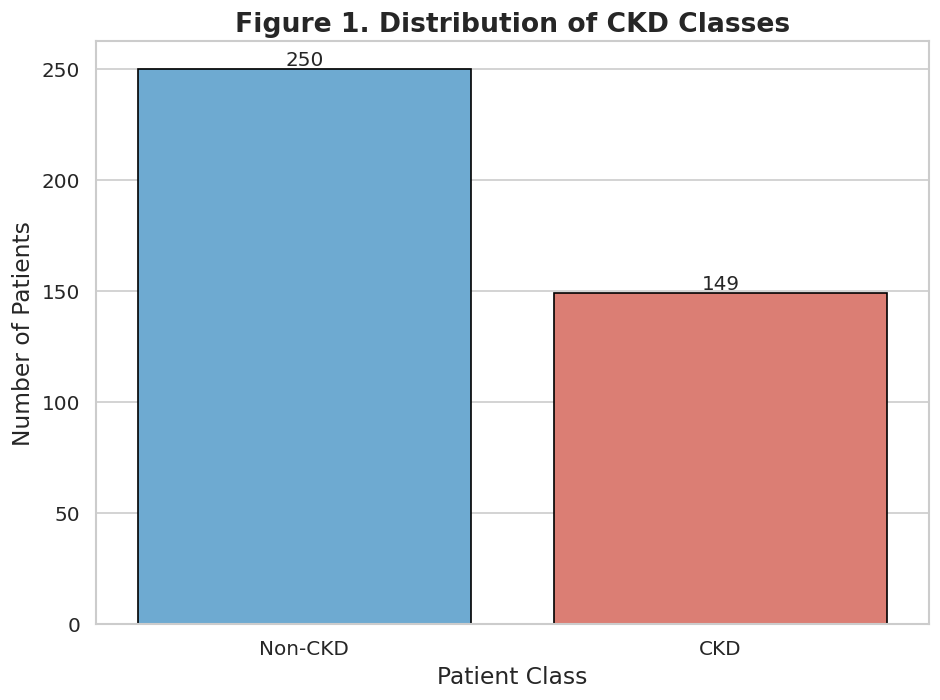

In [25]:
# =============================================================================
# Figure 01 : Class Distribution
# =============================================================================

plt.figure(figsize=(8,6))

ax = sns.countplot(

    data=eda_df,

    x=target_col,

    order=["Non-CKD","CKD"],

    palette=["#5DADE2","#EC7063"],

    edgecolor="black"

)

for container in ax.containers:
    ax.bar_label(container, fontsize=12)

plt.title(

    "Figure 1. Distribution of CKD Classes",

    fontsize=16,

    weight="bold"

)

plt.xlabel("Patient Class")

plt.ylabel("Number of Patients")

plt.tight_layout()

plt.savefig(

    os.path.join(

        figure_path,

        "Figure_01_Class_Distribution.png"

    ),

    dpi=300,

    bbox_inches="tight"

)

plt.show()

In [26]:
# =============================================================================
# Save Target Summary
# =============================================================================

target_summary.to_csv(

    os.path.join(

        result_path,

        "Target_Class_Summary.csv"

    ),

    index=False

)

print("Target summary saved successfully.")

Target summary saved successfully.


In [27]:
# =============================================================================
# Comprehensive Descriptive Statistics
# =============================================================================

# Select only numerical features (excluding target)
numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

if "class" in numerical_features:
    numerical_features.remove("class")

# Create summary table
summary = pd.DataFrame(index=numerical_features)

summary["Mean"] = df[numerical_features].mean()
summary["Median"] = df[numerical_features].median()
summary["Std. Dev."] = df[numerical_features].std()

summary["Minimum"] = df[numerical_features].min()
summary["Q1 (25%)"] = df[numerical_features].quantile(0.25)
summary["Q2 (Median)"] = df[numerical_features].median()
summary["Q3 (75%)"] = df[numerical_features].quantile(0.75)
summary["Maximum"] = df[numerical_features].max()

summary["Variance"] = df[numerical_features].var()
summary["Skewness"] = df[numerical_features].skew()
summary["Kurtosis"] = df[numerical_features].kurt()

summary["CV (%)"] = (
    summary["Std. Dev."] /
    summary["Mean"].replace(0, np.nan)
).abs() * 100

summary = summary.round(3)

display(summary)

,Mean,Median,Std. Dev.,Minimum,Q1 (25%),Q2 (Median),Q3 (75%),Maximum,Variance,Skewness,Kurtosis,CV (%)
age,51.492,54.500,16.961,2.000,42.000,54.500,64.00,90.000,287.690,-0.687,0.139,32.940
bp,76.591,80.000,13.503,50.000,70.000,80.000,80.00,180.000,182.323,1.598,8.881,17.629
sg,1.017,1.017,0.005,1.005,1.015,1.017,1.02,1.025,0.000,-0.180,-0.898,0.528
al,0.902,0.000,1.314,0.000,0.000,0.000,2.00,5.000,1.727,1.176,0.014,145.635
su,0.396,0.000,1.041,0.000,0.000,0.000,0.00,5.000,1.084,2.695,6.342,262.925
rbc,0.882,1.000,0.323,0.000,1.000,1.000,1.00,1.000,0.104,-2.380,3.684,36.587
pc,0.810,1.000,0.393,0.000,1.000,1.000,1.00,1.000,0.155,-1.582,0.507,48.568
pcc,0.105,0.000,0.307,0.000,0.000,0.000,0.00,1.000,0.094,2.582,4.691,291.914
ba,0.055,0.000,0.229,0.000,0.000,0.000,0.00,1.000,0.052,3.913,13.377,414.481
bgr,145.158,121.000,75.331,22.000,101.000,121.000,150.00,490.000,5674.766,2.200,5.230,51.896


In [ ]:
# =============================================================================
# Save Descriptive Statistics
# =============================================================================

summary.to_csv(
    os.path.join(
        result_path,
        "Descriptive_Statistics.csv"
    )
)

print("Descriptive statistics saved successfully.")

Descriptive statistics saved successfully.


In [28]:
# =============================================================================
# Most Skewed Numerical Features
# =============================================================================

skew_table = (
    summary["Skewness"]
    .abs()
    .sort_values(ascending=False)
    .to_frame(name="Absolute Skewness")
)

display(skew_table)

,Absolute Skewness
pot,13.121
sod,7.929
sc,7.658
ba,3.913
cad,2.982
bu,2.720
su,2.695
pcc,2.582
rbc,2.380
bgr,2.200


In [29]:
# =============================================================================
# Coefficient of Variation Ranking
# =============================================================================

cv_table = (
    summary["CV (%)"]
    .sort_values(ascending=False)
    .to_frame(name="Coefficient of Variation (%)")
)

display(cv_table)

,Coefficient of Variation (%)
ba,414.481
cad,328.059
pcc,291.914
su,262.925
ane,237.996
pe,206.414
appet,196.865
sc,187.665
al,145.635
dm,138.463


In [30]:
# =============================================================================
# Save Research Tables
# =============================================================================

skew_table.to_csv(
    os.path.join(
        result_path,
        "Feature_Skewness.csv"
    )
)

cv_table.to_csv(
    os.path.join(
        result_path,
        "Feature_Coefficient_of_Variation.csv"
    )
)

print("Research tables exported successfully.")

Research tables exported successfully.


In [31]:
# =============================================================================
# Create Figure Directory for Numerical Distributions
# =============================================================================

distribution_path = os.path.join(
    figure_path,
    "Numerical_Distributions"
)

os.makedirs(distribution_path, exist_ok=True)

print("Distribution folder created successfully.")

Distribution folder created successfully.


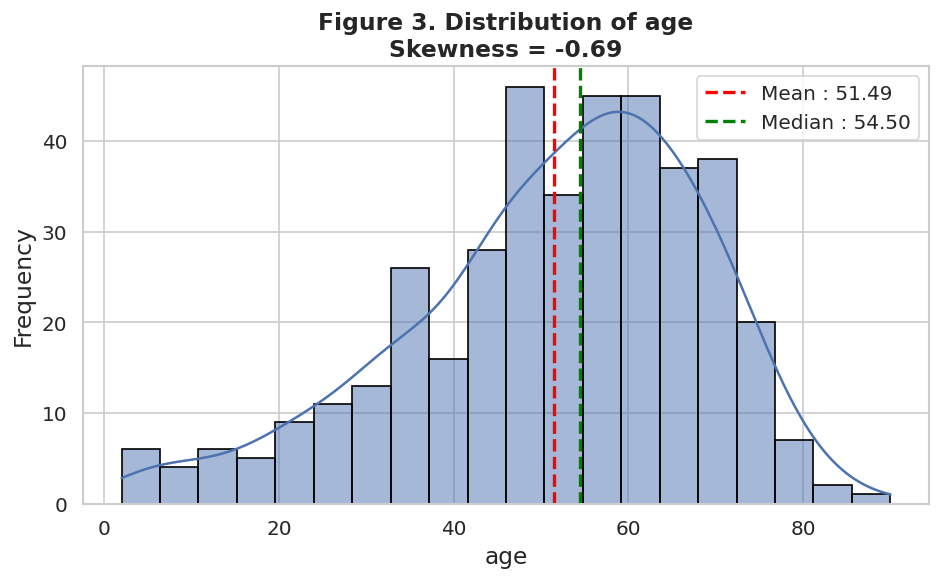

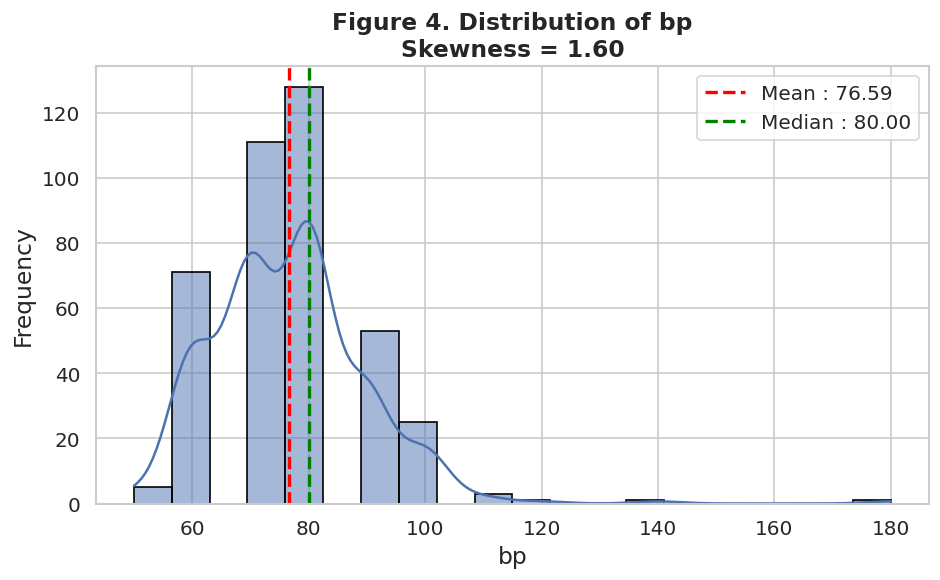

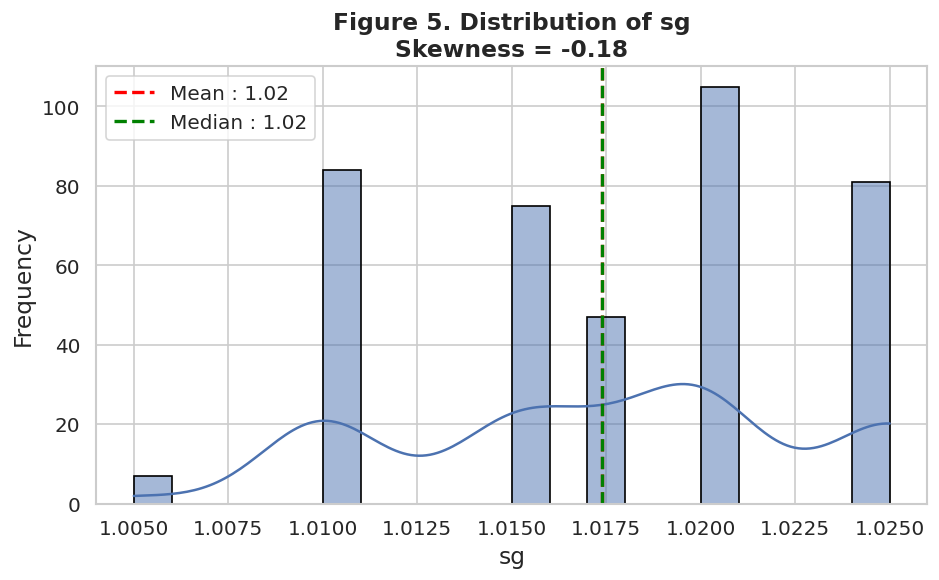

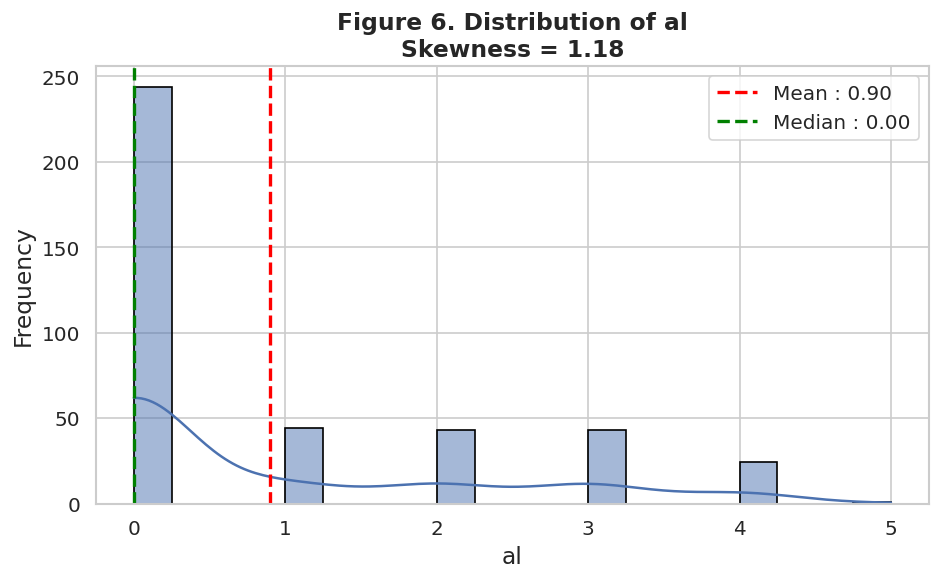

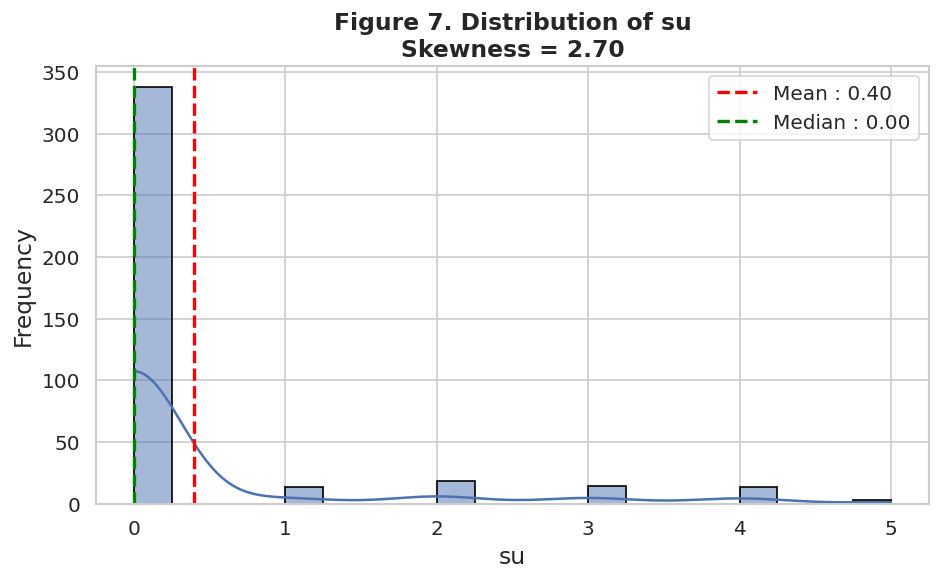

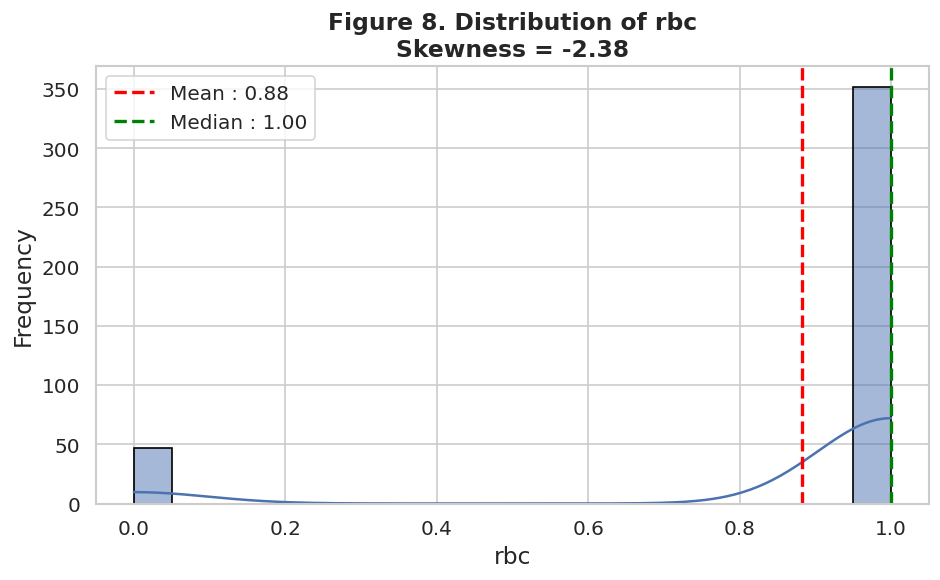

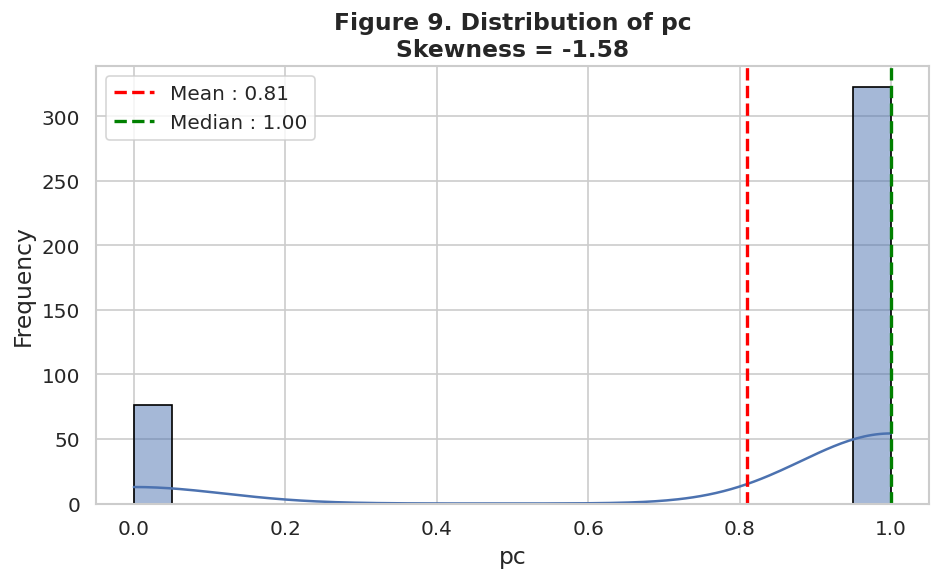

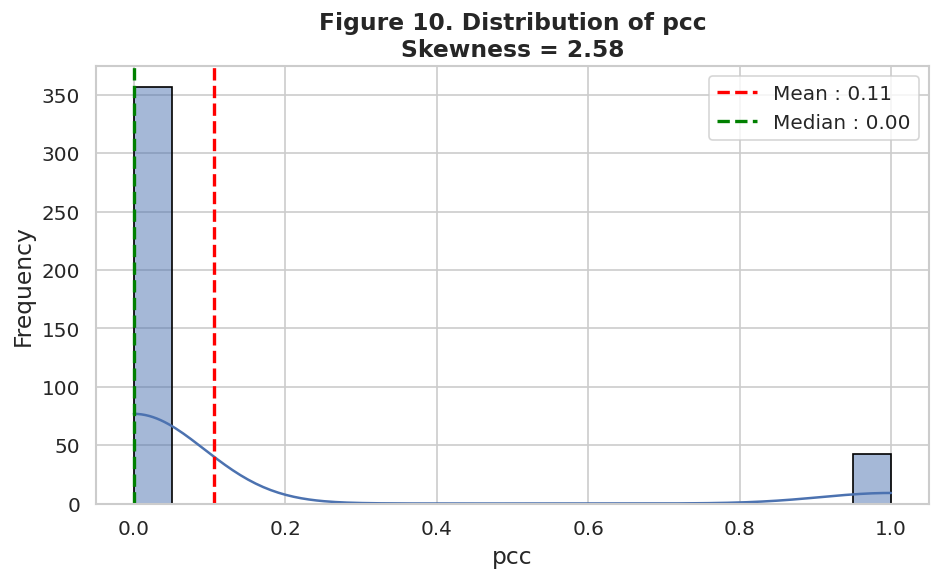

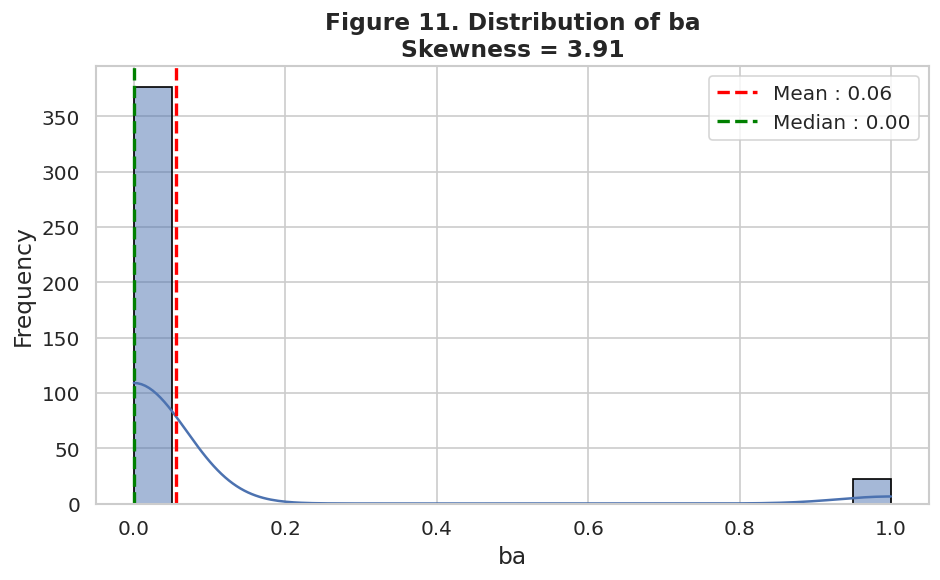

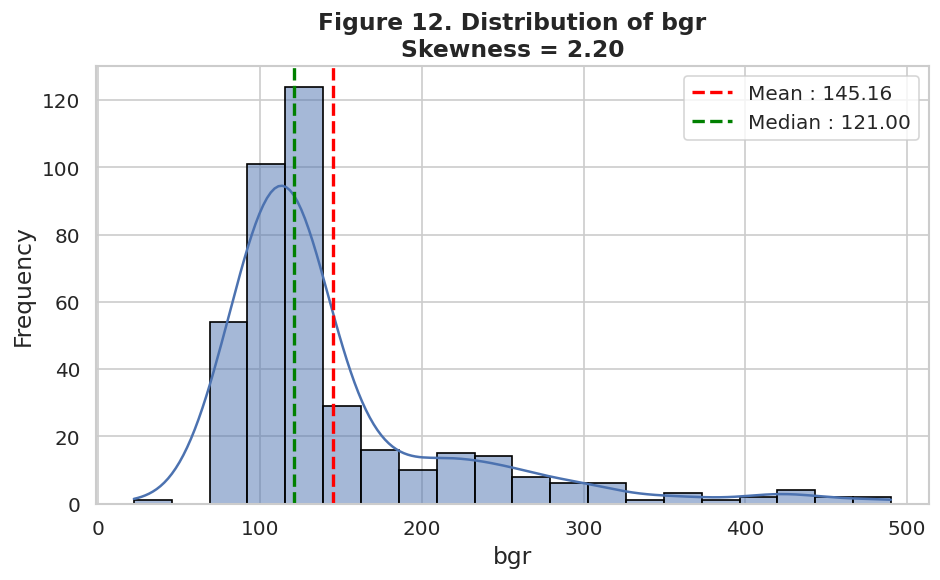

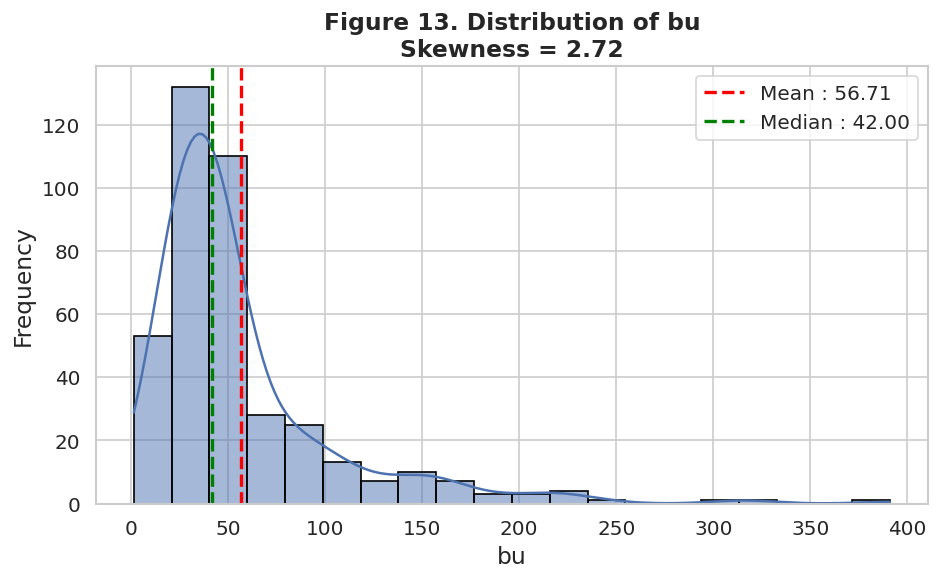

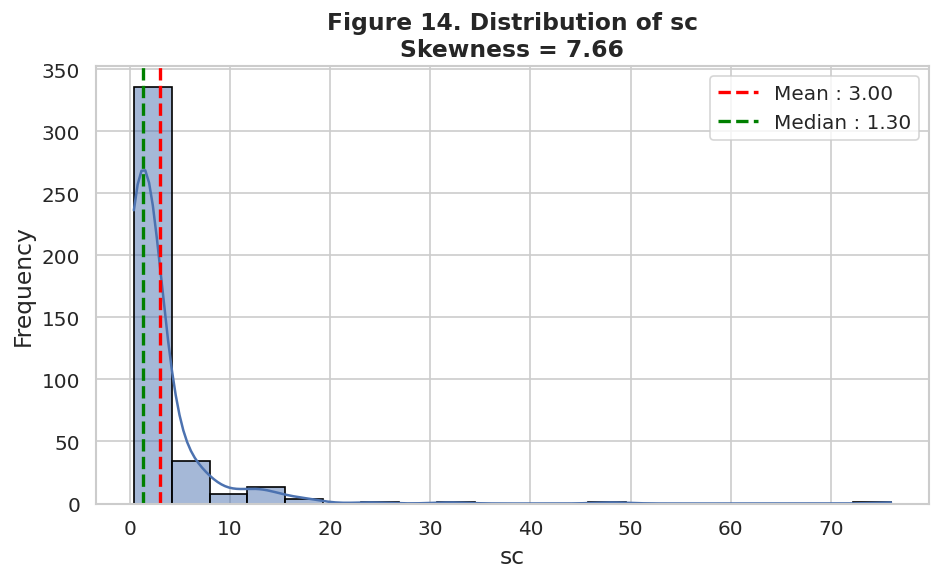

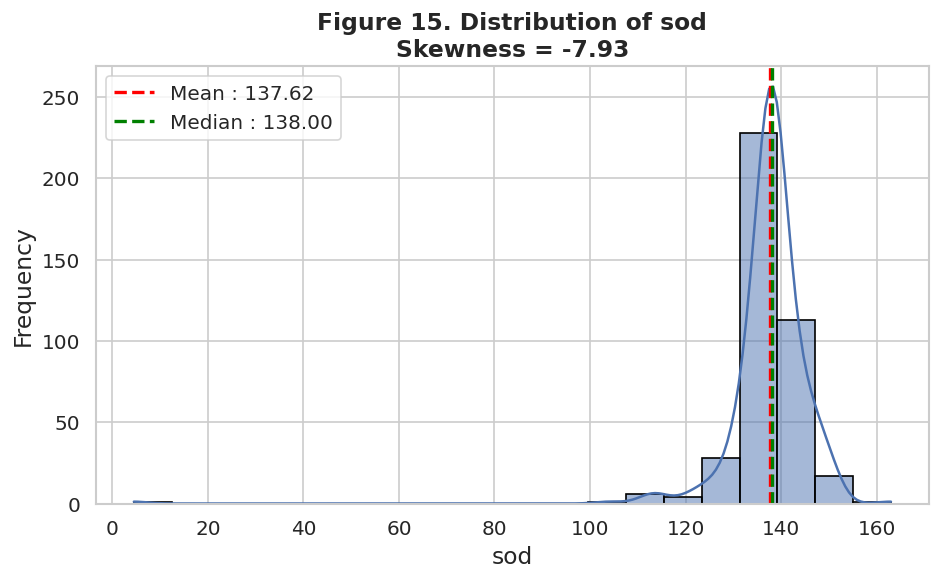

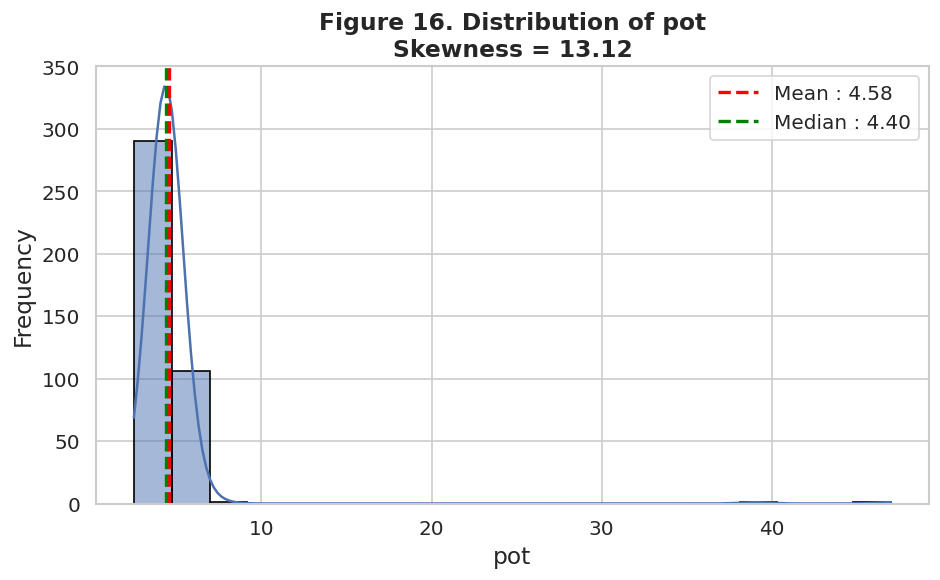

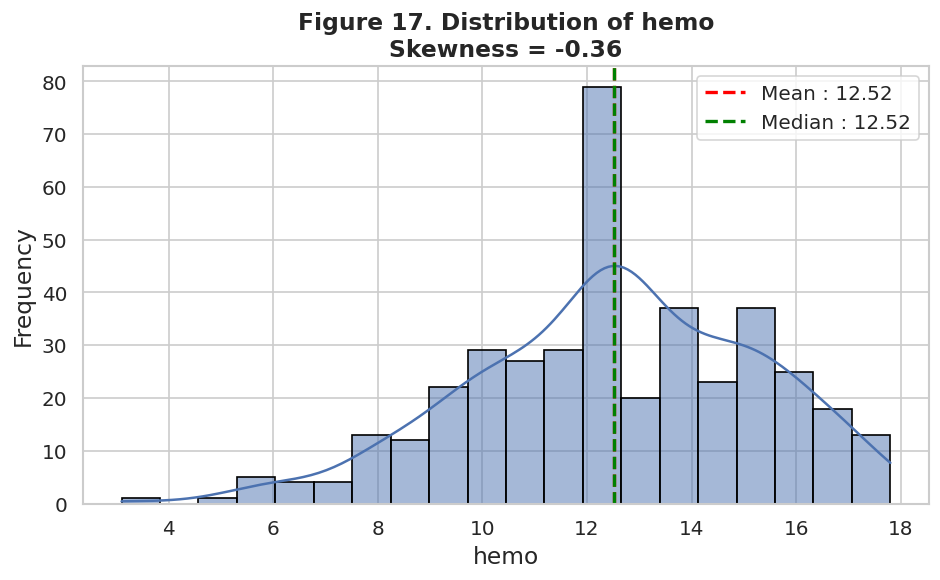

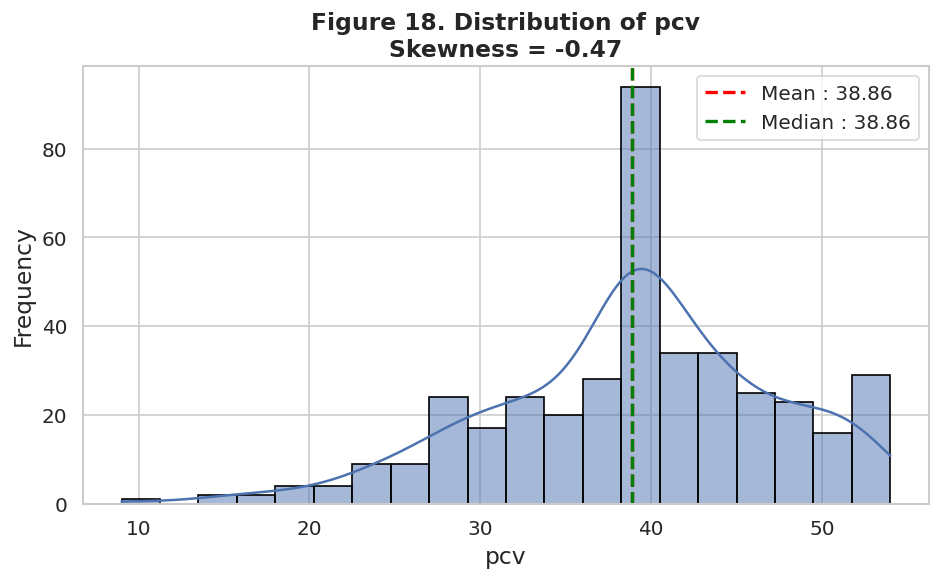

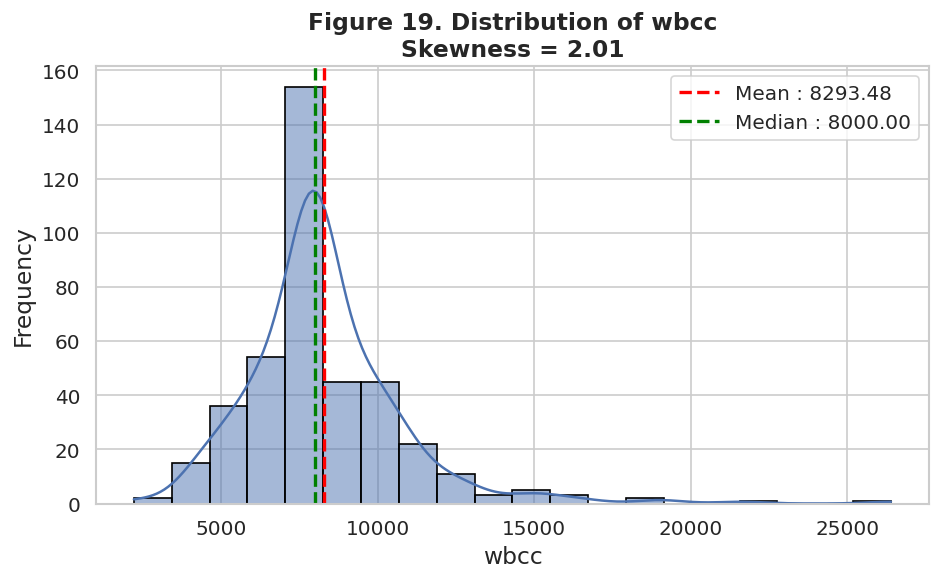

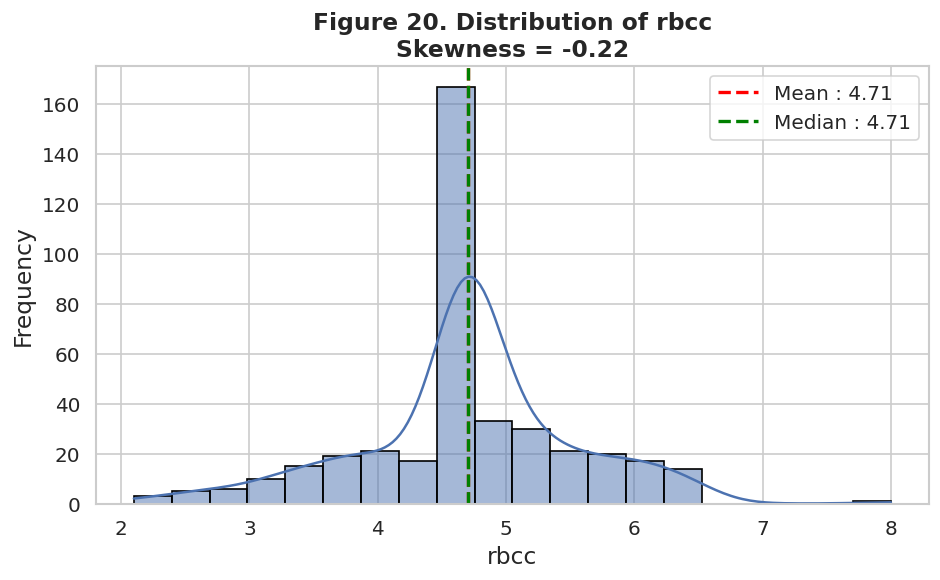

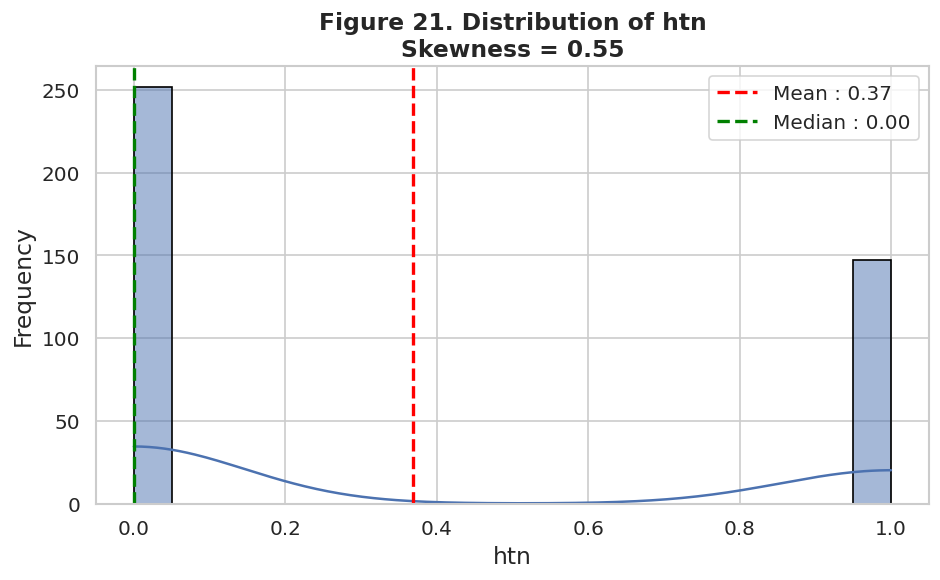

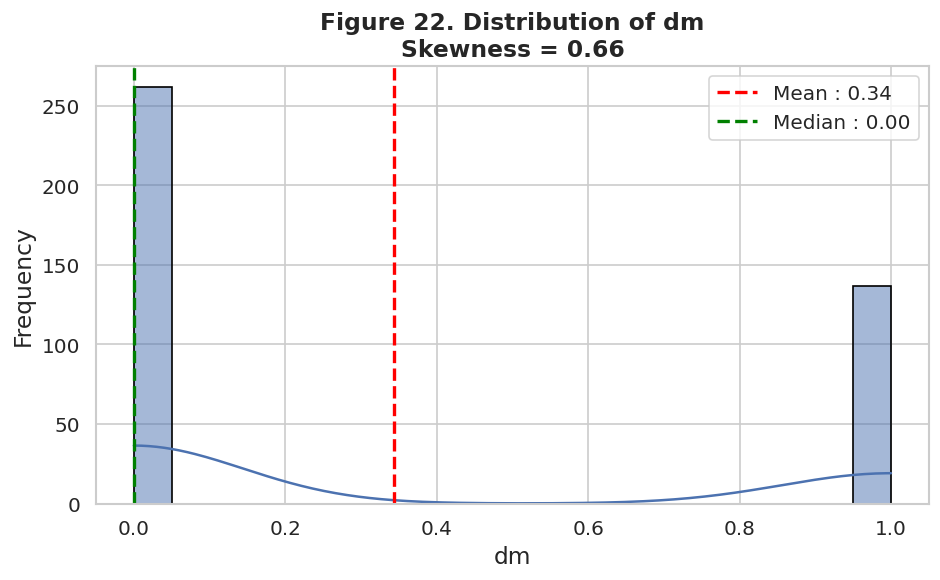

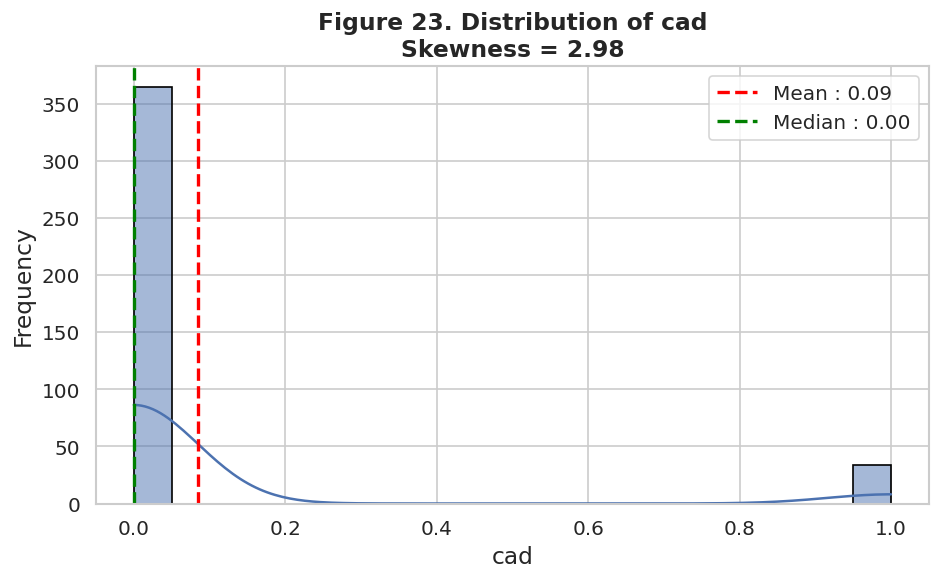

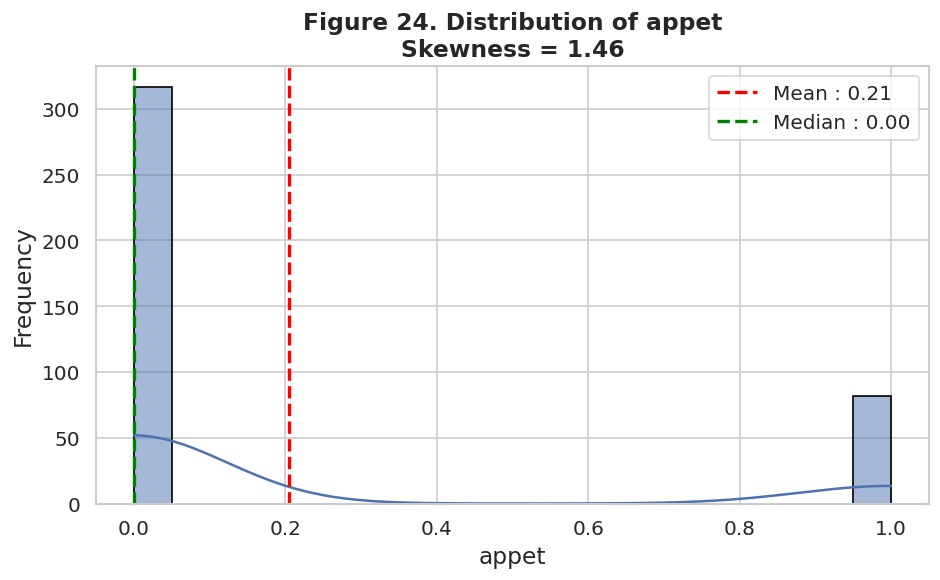

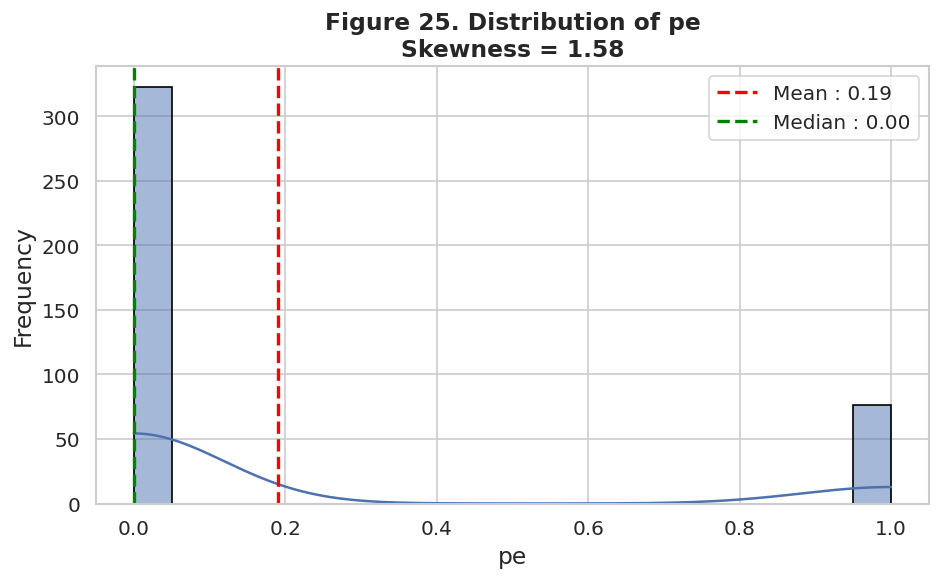

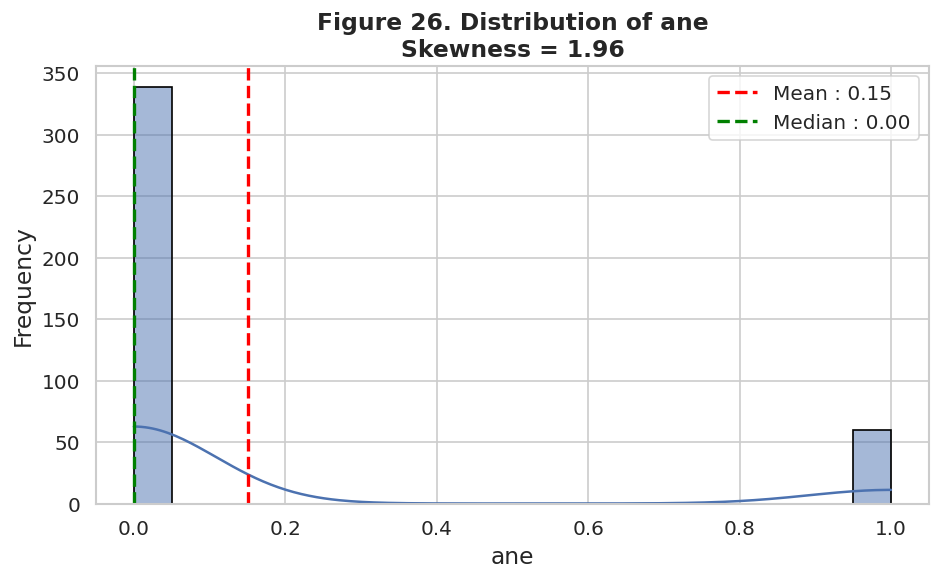

In [32]:
# =============================================================================
# Publication-Quality Distribution Plots
# =============================================================================

distribution_summary = []

for i, feature in enumerate(numerical_features, start=1):

    plt.figure(figsize=(8,5))

    sns.histplot(
        df[feature],
        kde=True,
        bins=20,
        color="#4C72B0",
        edgecolor="black"
    )

    mean_value = df[feature].mean()
    median_value = df[feature].median()
    skew_value = df[feature].skew()

    plt.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean : {mean_value:.2f}"
    )

    plt.axvline(
        median_value,
        color="green",
        linestyle="--",
        linewidth=2,
        label=f"Median : {median_value:.2f}"
    )

    plt.title(
        f"Figure {i+2}. Distribution of {feature}\n"
        f"Skewness = {skew_value:.2f}",
        fontsize=14,
        weight="bold"
    )

    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            distribution_path,
            f"Figure_{i+2}_{feature}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    distribution_summary.append([
        feature,
        round(skew_value,3)
    ])

In [33]:
# =============================================================================
# Distribution Summary
# =============================================================================

distribution_summary = pd.DataFrame(

    distribution_summary,

    columns=[
        "Feature",
        "Skewness"
    ]

)

display(distribution_summary)

,Feature,Skewness
0,age,-0.687
1,bp,1.598
2,sg,-0.180
3,al,1.176
4,su,2.695
5,rbc,-2.380
6,pc,-1.582
7,pcc,2.582
8,ba,3.913
9,bgr,2.200


In [ ]:
# =============================================================================
# Save Distribution Summary
# =============================================================================

distribution_summary.to_csv(

    os.path.join(

        result_path,

        "Distribution_Summary.csv"

    ),

    index=False

)

print("Distribution summary exported.")

Distribution summary exported.


In [34]:
# =============================================================================
# Identify Numerical Features
# =============================================================================

numerical_features = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Exclude target variable
if "class" in numerical_features:
    numerical_features.remove("class")

print(f"Total Numerical Features : {len(numerical_features)}")
print(numerical_features)

Total Numerical Features : 24
['age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


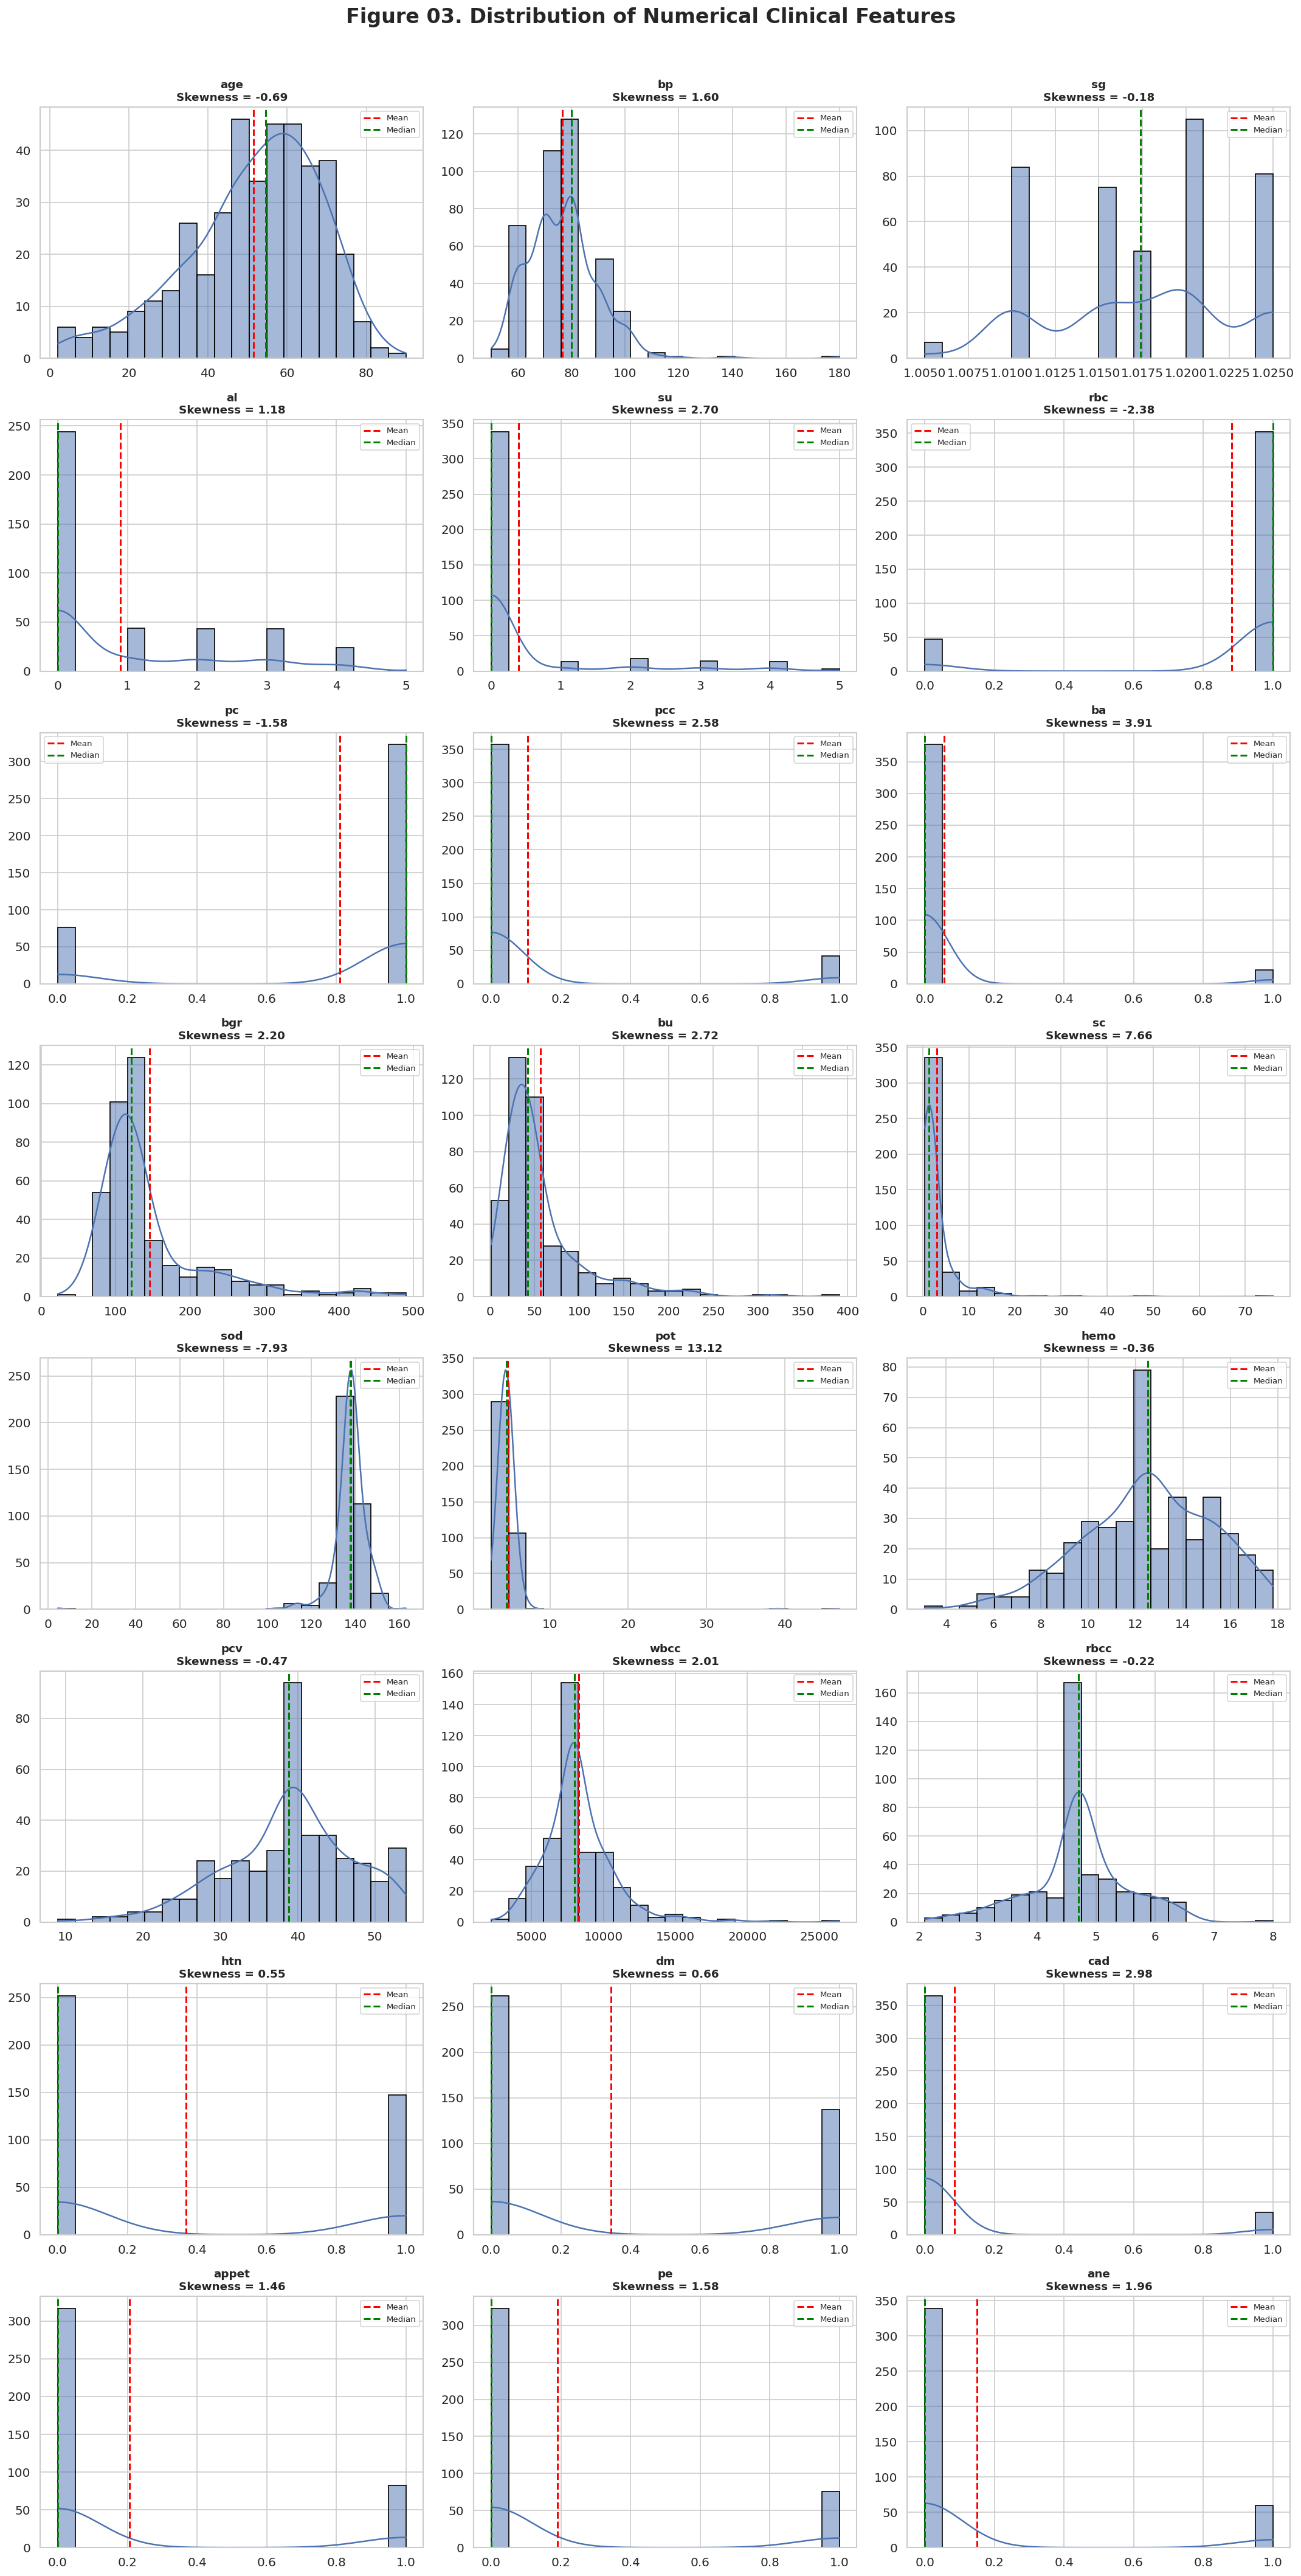

In [35]:
# =============================================================================
# Figure 03 : Distribution of Numerical Features
# =============================================================================

import math

n_features = len(numerical_features)
n_cols = 3
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.5 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(numerical_features):

    ax = axes[i]

    sns.histplot(
        df[feature],
        bins=20,
        kde=True,
        ax=ax,
        color="#4C72B0",
        edgecolor="black"
    )

    mean_value = df[feature].mean()
    median_value = df[feature].median()

    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=1.8,
        label="Mean"
    )

    ax.axvline(
        median_value,
        color="green",
        linestyle="--",
        linewidth=1.8,
        label="Median"
    )

    skewness = df[feature].skew()

    ax.set_title(
        f"{feature}\nSkewness = {skewness:.2f}",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("")

    ax.legend(fontsize=8)

# Remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Figure 03. Distribution of Numerical Clinical Features",
    fontsize=20,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_03_Numerical_Distributions.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

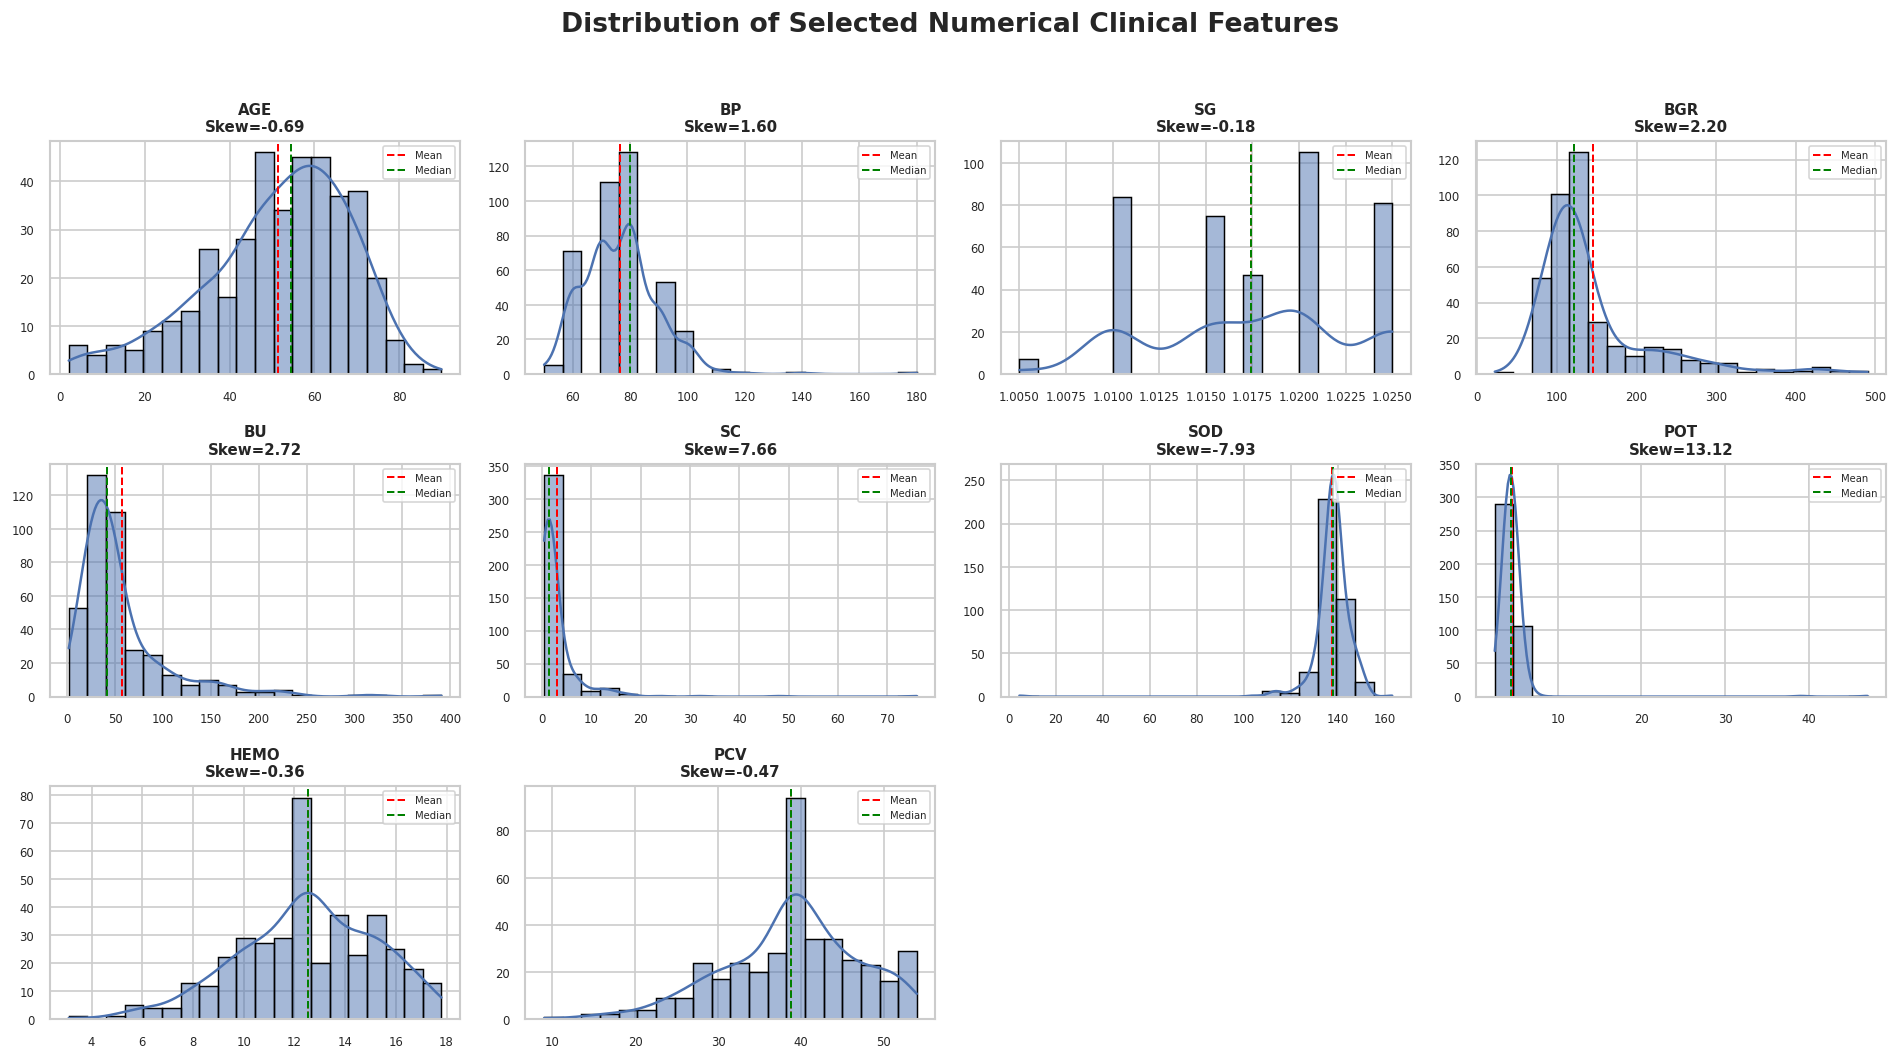

In [36]:
# =============================================================================
# Figure 03 : Distribution of Selected Numerical Clinical Features
# =============================================================================

import math
import matplotlib.pyplot as plt
import seaborn as sns
import os

# -------------------------------------------------------------------------
# Select the most important numerical features
# -------------------------------------------------------------------------

selected_features = [
    "age",
    "bp",
    "sg",
    "bgr",
    "bu",
    "sc",
    "sod",
    "pot",
    "hemo",
    "pcv"
]

# -------------------------------------------------------------------------
# Figure Layout
# -------------------------------------------------------------------------

n_features = len(selected_features)
n_cols = 4
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 9)
)

axes = axes.flatten()

# -------------------------------------------------------------------------
# Plot Histograms
# -------------------------------------------------------------------------

for i, feature in enumerate(selected_features):

    ax = axes[i]

    sns.histplot(
        df[feature],
        bins=20,
        kde=True,
        color="#4C72B0",
        edgecolor="black",
        ax=ax
    )

    mean_value = df[feature].mean()
    median_value = df[feature].median()

    # Mean Line
    ax.axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Mean"
    )

    # Median Line
    ax.axvline(
        median_value,
        color="green",
        linestyle="--",
        linewidth=1.2,
        label="Median"
    )

    skewness = df[feature].skew()

    ax.set_title(
        f"{feature.upper()}\nSkew={skewness:.2f}",
        fontsize=9,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=7)

    ax.legend(
        fontsize=6,
        loc="upper right",
        frameon=True
    )

# -------------------------------------------------------------------------
# Remove Empty Subplots
# -------------------------------------------------------------------------

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# -------------------------------------------------------------------------
# Figure Title
# -------------------------------------------------------------------------

fig.suptitle(
    "Distribution of Selected Numerical Clinical Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# -------------------------------------------------------------------------
# Save Figure
# -------------------------------------------------------------------------

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_03_Numerical_Distributions.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =============================================================================
# Numerical Feature Distribution Summary
# =============================================================================

distribution_summary = pd.DataFrame({

    "Feature": numerical_features,

    "Mean": [df[col].mean() for col in numerical_features],

    "Median": [df[col].median() for col in numerical_features],

    "Standard Deviation": [df[col].std() for col in numerical_features],

    "Skewness": [df[col].skew() for col in numerical_features]

})

distribution_summary = distribution_summary.round(3)

display(distribution_summary)

,Feature,Mean,Median,Standard Deviation,Skewness
0,age,51.492,54.500,16.961,-0.687
1,bp,76.591,80.000,13.503,1.598
2,sg,1.017,1.017,0.005,-0.180
3,al,0.902,0.000,1.314,1.176
4,su,0.396,0.000,1.041,2.695
5,rbc,0.882,1.000,0.323,-2.380
6,pc,0.810,1.000,0.393,-1.582
7,pcc,0.105,0.000,0.307,2.582
8,ba,0.055,0.000,0.229,3.913
9,bgr,145.158,121.000,75.331,2.200


In [ ]:
# =============================================================================
# Save Distribution Summary
# =============================================================================

distribution_summary.to_csv(
    os.path.join(
        result_path,
        "Numerical_Distribution_Summary.csv"
    ),
    index=False
)

print("Distribution summary saved successfully.")

Distribution summary saved successfully.


In [ ]:
## Research Interpretation

The distribution plots demonstrate considerable heterogeneity among the numerical clinical variables. Several biochemical indicators, including serum creatinine, blood urea, and blood glucose, exhibit pronounced right-skewed distributions, reflecting the presence of patients with markedly elevated laboratory values. In contrast, variables such as age and blood pressure appear comparatively symmetric.

The observed distributional characteristics are consistent with the descriptive statistical analysis presented in the previous section and are commonly reported in biomedical datasets. These findings provide valuable insight into feature behavior and support subsequent analyses, including correlation assessment, outlier detection, and predictive model development.

In [ ]:
# =============================================================================
# Continuous Numerical Features for Correlation Analysis
# =============================================================================

continuous_features = [
    "age",
    "bp",
    "bgr",
    "bu",
    "sc",
    "sod",
    "pot",
    "hemo",
    "pcv",
    "wbcc",
    "rbcc"
]

# Verify that all selected columns exist
continuous_features = [
    col for col in continuous_features if col in df.columns
]

print(f"Total Continuous Features: {len(continuous_features)}")
print(continuous_features)

Total Continuous Features: 11
['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']


In [ ]:
# =============================================================================
# Pearson Correlation Matrix
# =============================================================================

corr_matrix = df[continuous_features].corr(method="pearson")

display(corr_matrix.round(3))

,age,bp,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc
age,1.000,0.138,0.233,0.195,0.136,-0.089,0.051,-0.180,-0.218,0.091,-0.203
bp,0.138,1.000,0.150,0.181,0.143,-0.100,0.063,-0.279,-0.292,0.023,-0.220
bgr,0.233,0.150,1.000,0.119,0.068,-0.130,0.052,-0.255,-0.260,0.121,-0.217
bu,0.195,0.181,0.119,1.000,0.581,-0.309,0.340,-0.542,-0.527,0.039,-0.467
sc,0.136,0.143,0.068,0.581,1.000,-0.624,0.204,-0.343,-0.342,-0.010,-0.325
sod,-0.089,-0.100,-0.130,-0.309,-0.624,1.000,0.070,0.331,0.344,0.007,0.317
pot,0.051,0.063,0.052,0.340,0.204,0.070,1.000,-0.097,-0.120,-0.075,-0.119
hemo,-0.180,-0.279,-0.255,-0.542,-0.343,0.331,-0.097,1.000,0.855,-0.139,0.682
pcv,-0.218,-0.292,-0.260,-0.527,-0.342,0.344,-0.120,0.855,1.000,-0.175,0.704
wbcc,0.091,0.023,0.121,0.039,-0.010,0.007,-0.075,-0.139,-0.175,1.000,-0.150


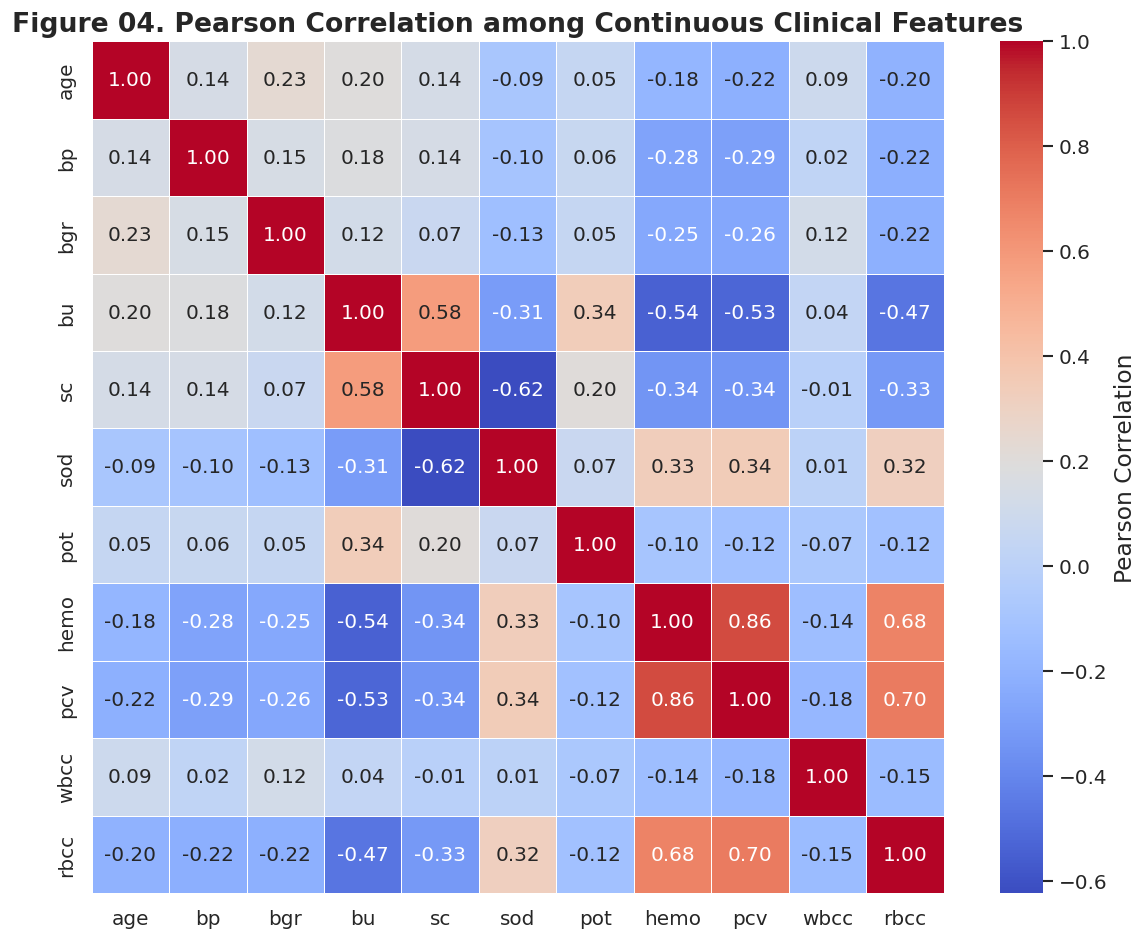

In [ ]:
# =============================================================================
# Figure 04 : Pearson Correlation Heatmap
# =============================================================================

plt.figure(figsize=(10,8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Figure 04. Pearson Correlation among Continuous Clinical Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_04_Correlation_Heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =============================================================================
# Strong Correlation Pairs (|r| ≥ 0.70)
# =============================================================================

corr_pairs = (
    corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

strong_corr = (
    corr_pairs[
        corr_pairs["Correlation"].abs() >= 0.70
    ]
    .sort_values(
        by="Correlation",
        key=lambda x: x.abs(),
        ascending=False
    )
)

display(strong_corr)

,Feature 1,Feature 2,Correlation
49,hemo,pcv,0.855215
53,pcv,rbcc,0.704107


In [ ]:
# =============================================================================
# Save Correlation Results
# =============================================================================

corr_matrix.to_csv(
    os.path.join(
        result_path,
        "Pearson_Correlation_Matrix.csv"
    )
)

strong_corr.to_csv(
    os.path.join(
        result_path,
        "Strong_Correlation_Pairs.csv"
    ),
    index=False
)

print("Correlation results saved successfully.")

Correlation results saved successfully.


In [ ]:
# =============================================================================
# Correlation with Target Variable
# =============================================================================

# Exclude target column itself
feature_target_corr = (
    df.corr(numeric_only=True)["class"]
    .drop("class")
    .sort_values(key=abs, ascending=False)
)

feature_target_corr = feature_target_corr.round(3)

display(feature_target_corr.to_frame(name="Correlation with CKD"))

,Correlation with CKD
hemo,0.730
sg,0.699
pcv,0.690
rbcc,0.592
htn,-0.590
dm,-0.558
al,-0.531
appet,-0.393
bgr,-0.379
pc,0.374


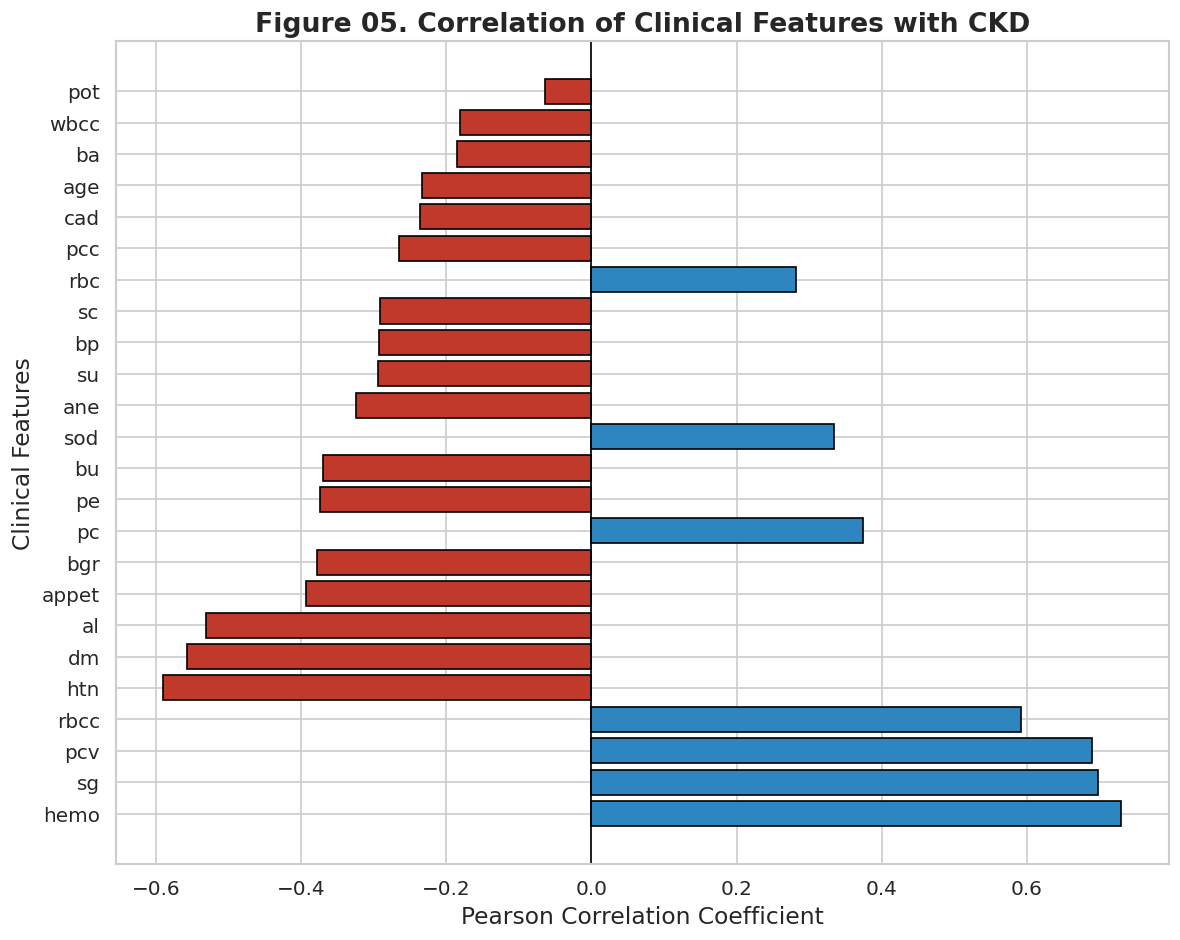

In [ ]:
# =============================================================================
# Figure 05 : Feature Correlation with CKD
# =============================================================================

plt.figure(figsize=(10,8))

colors = [
    "#C0392B" if value < 0 else "#2E86C1"
    for value in feature_target_corr.values
]

plt.barh(
    feature_target_corr.index,
    feature_target_corr.values,
    color=colors,
    edgecolor="black"
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Clinical Features")

plt.title(
    "Figure 05. Correlation of Clinical Features with CKD",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_05_Feature_Target_Correlation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =============================================================================
# Top Features Associated with CKD
# =============================================================================

top_features = (
    feature_target_corr
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

display(top_features.to_frame(name="Absolute Correlation"))

,Absolute Correlation
hemo,0.730
sg,0.699
pcv,0.690
rbcc,0.592
htn,0.590
dm,0.558
al,0.531
appet,0.393
bgr,0.379
pc,0.374


In [ ]:
# =============================================================================
# Save Target Association Results
# =============================================================================

feature_target_corr.to_csv(
    os.path.join(
        result_path,
        "Feature_Target_Correlation.csv"
    )
)

top_features.to_csv(
    os.path.join(
        result_path,
        "Top10_Target_Correlated_Features.csv"
    )
)

print("Target association results exported successfully.")

Target association results exported successfully.


In [ ]:
## Research Interpretation

The correlation analysis with the target variable identifies the clinical attributes that exhibit the strongest association with CKD diagnosis. Features with larger absolute correlation coefficients are likely to possess greater discriminative capability and may contribute more significantly to predictive modeling.

These findings provide preliminary evidence regarding feature relevance and complement subsequent machine learning-based feature importance analyses. Nevertheless, correlation analysis alone does not establish causal relationships and should be interpreted alongside domain knowledge and model-based explanations.

In [ ]:
### Key Findings

- Pearson correlation coefficients between clinical features and CKD status were computed.
- The ten most strongly associated features were identified.
- A publication-quality visualization was generated and saved.
- Correlation results were exported for feature selection and reporting.

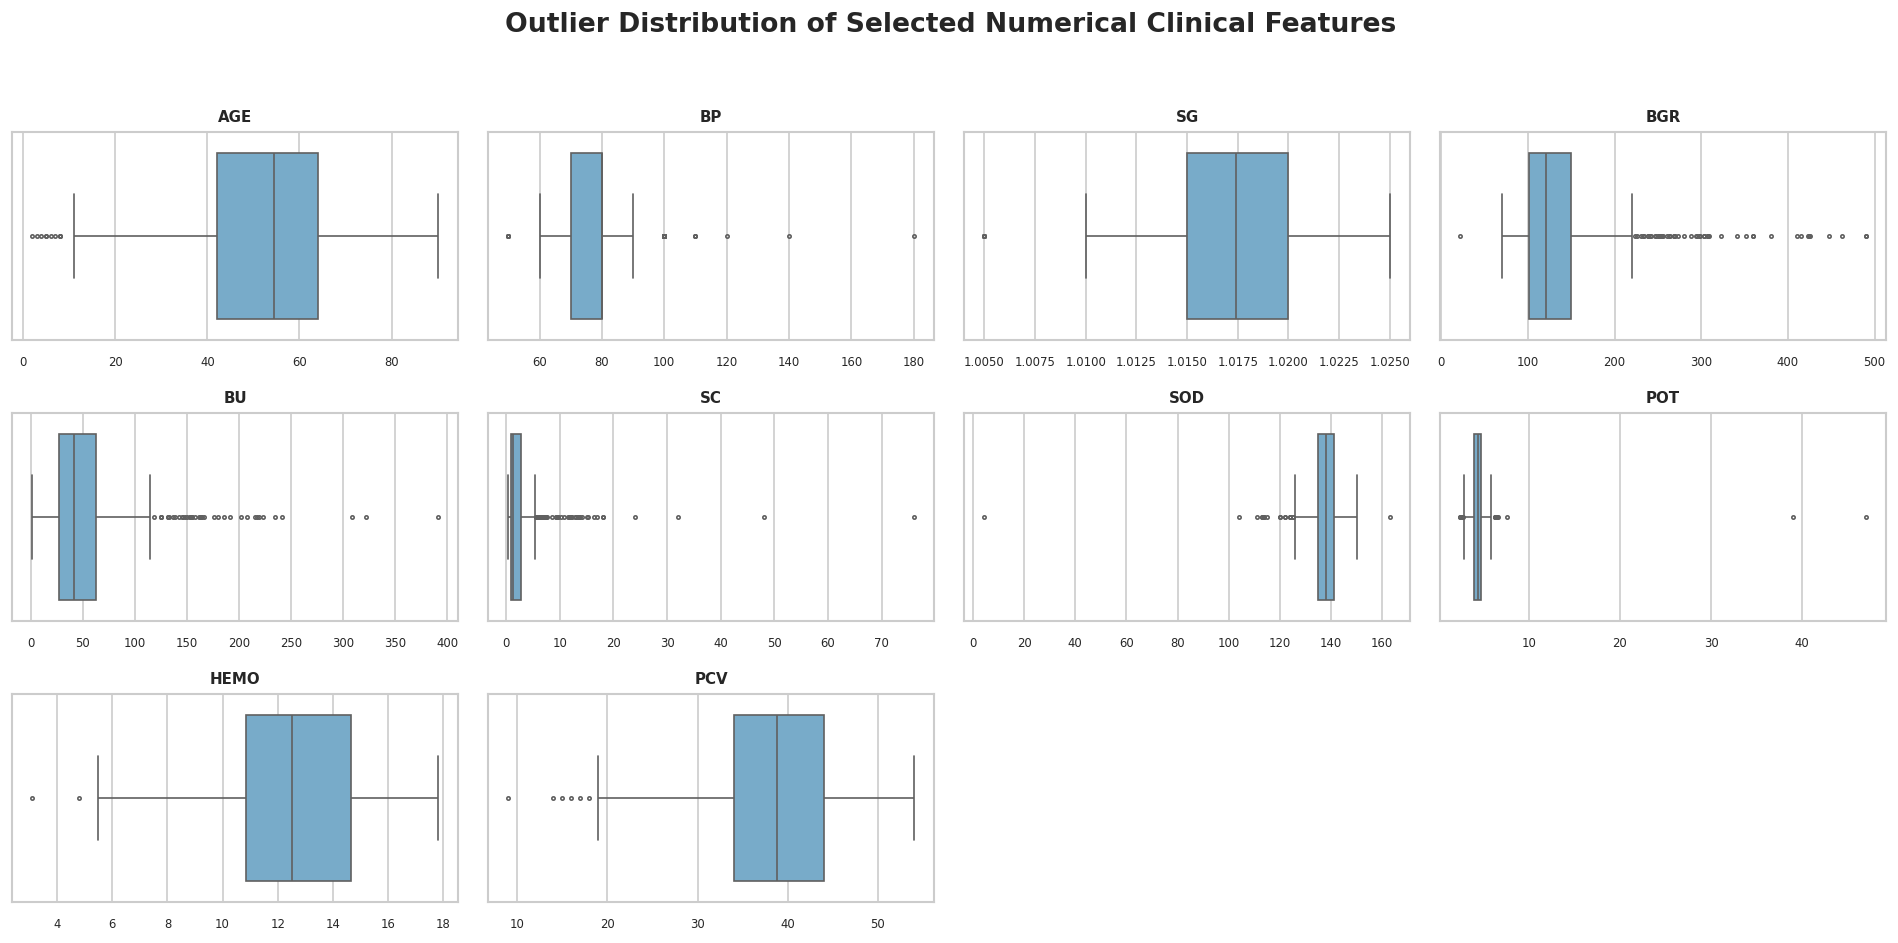

In [37]:
# =============================================================================
# Figure 06 : Outlier Analysis Using Selected Clinical Features
# =============================================================================

import math
import matplotlib.pyplot as plt
import seaborn as sns
import os

# -------------------------------------------------------------------------
# Selected Numerical Features
# -------------------------------------------------------------------------

selected_features = [
    "age",
    "bp",
    "sg",
    "bgr",
    "bu",
    "sc",
    "sod",
    "pot",
    "hemo",
    "pcv"
]

# -------------------------------------------------------------------------
# Figure Layout
# -------------------------------------------------------------------------

n_features = len(selected_features)
n_cols = 4
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 8)
)

axes = axes.flatten()

# -------------------------------------------------------------------------
# Draw Boxplots
# -------------------------------------------------------------------------

for i, feature in enumerate(selected_features):

    sns.boxplot(
        x=df[feature],
        ax=axes[i],
        color="#6BAED6",
        linewidth=1,
        fliersize=2
    )

    axes[i].set_title(
        feature.upper(),
        fontsize=9,
        fontweight="bold"
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis='x', labelsize=7)

# -------------------------------------------------------------------------
# Remove Empty Axes
# -------------------------------------------------------------------------

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# -------------------------------------------------------------------------
# Figure Title
# -------------------------------------------------------------------------

fig.suptitle(
    "Outlier Distribution of Selected Numerical Clinical Features",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# -------------------------------------------------------------------------
# Save Figure
# -------------------------------------------------------------------------

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_06_Boxplot_Outlier.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =============================================================================
# IQR-Based Outlier Summary
# =============================================================================

outlier_summary = []

for feature in numerical_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    percentage = (outliers / len(df)) * 100

    outlier_summary.append([
        feature,
        round(lower_bound,2),
        round(upper_bound,2),
        outliers,
        round(percentage,2)
    ])

outlier_summary = pd.DataFrame(

    outlier_summary,

    columns=[
        "Feature",
        "Lower Bound",
        "Upper Bound",
        "Outliers",
        "Outlier (%)"
    ]

)

display(outlier_summary)

,Feature,Lower Bound,Upper Bound,Outliers,Outlier (%)
0,age,9.00,97.00,10,2.51
1,bp,55.00,95.00,36,9.02
2,sg,1.01,1.03,7,1.75
3,al,-3.00,5.00,0,0.00
4,su,0.00,0.00,61,15.29
5,rbc,1.00,1.00,47,11.78
6,pc,1.00,1.00,76,19.05
7,pcc,0.00,0.00,42,10.53
8,ba,0.00,0.00,22,5.51
9,bgr,27.50,223.50,53,13.28


In [ ]:
# =============================================================================
# Save Outlier Summary
# =============================================================================

outlier_summary.to_csv(

    os.path.join(
        result_path,
        "Outlier_Summary.csv"
    ),

    index=False

)

print("Outlier summary exported successfully.")

Outlier summary exported successfully.


In [ ]:
## Research Interpretation

The boxplots reveal that several biochemical variables contain observations outside the interquartile range, indicating the presence of potential outliers. Such extreme values are expected in clinical datasets because patients may exhibit markedly different disease severities.

The IQR-based summary further quantifies the number and proportion of outliers for each feature. Rather than removing these observations, they are retained because they may represent clinically meaningful cases that contribute to robust CKD prediction.

In [ ]:
### Research Background

Categorical variables represent qualitative clinical observations such as hypertension, diabetes mellitus, appetite, and anemia status. Exploring their distributions provides valuable insights into the prevalence of different clinical conditions among CKD and non-CKD patients.

Frequency analysis complements numerical feature exploration by highlighting the composition of categorical attributes within the dataset.

In [ ]:
# =============================================================================
# Encoded Categorical Features
# =============================================================================

categorical_features = [
    "sg",
    "al",
    "su",
    "rbc",
    "pc",
    "pcc",
    "ba",
    "htn",
    "dm",
    "cad",
    "appet",
    "pe",
    "ane"
]

# Keep only existing columns
categorical_features = [
    col for col in categorical_features if col in df.columns
]

print(f"Total Categorical Features: {len(categorical_features)}")
print(categorical_features)

Total Categorical Features: 13
['sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


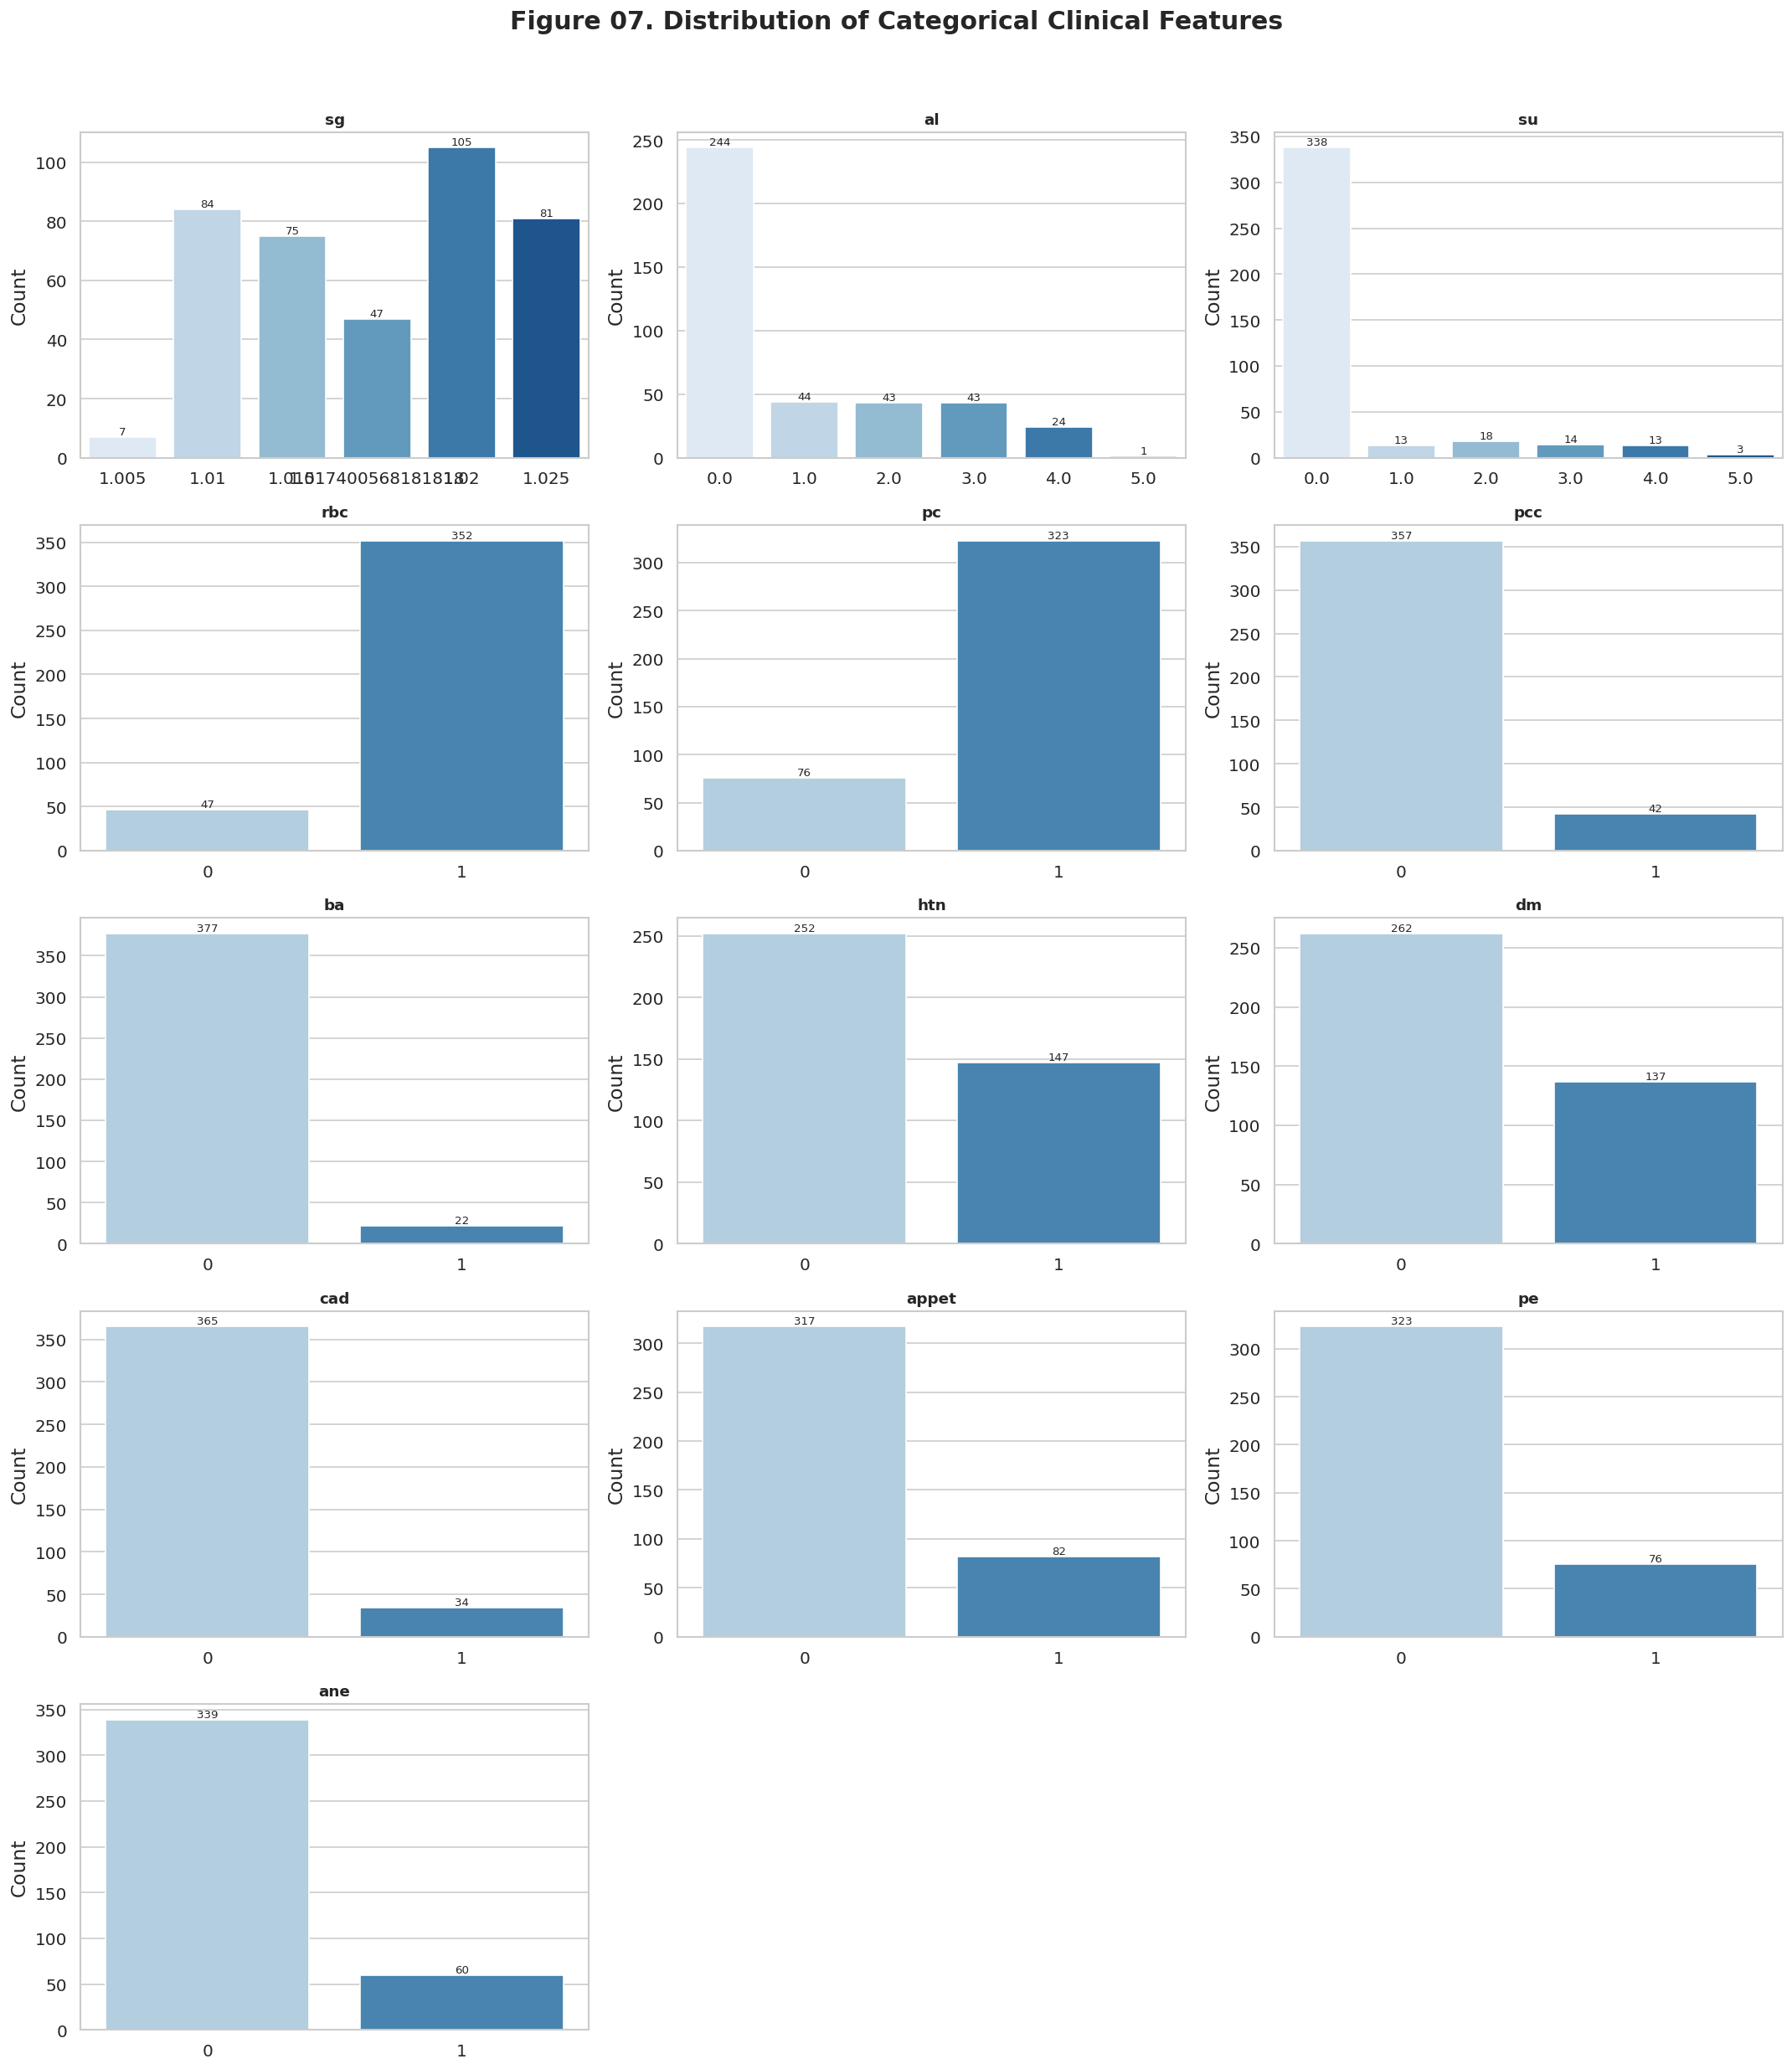

In [ ]:
# =============================================================================
# Figure 07 : Distribution of Categorical Features
# =============================================================================

import math

n_features = len(categorical_features)
n_cols = 3
n_rows = math.ceil(n_features / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4.2 * n_rows)
)

axes = axes.flatten()

for i, feature in enumerate(categorical_features):

    sns.countplot(
        x=df[feature],
        ax=axes[i],
        palette="Blues"
    )

    axes[i].set_title(
        feature,
        fontsize=11,
        fontweight="bold"
    )

    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")

    # Add count labels
    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fontsize=8
        )

# Remove unused subplot
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Figure 07. Distribution of Categorical Clinical Features",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0,0,1,0.96])

plt.savefig(
    os.path.join(
        figure_path,
        "Figure_07_Categorical_Distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =============================================================================
# Categorical Feature Summary
# =============================================================================

summary_rows = []

for feature in categorical_features:

    value_counts = df[feature].value_counts()

    dominant_category = value_counts.idxmax()
    dominant_count = value_counts.max()

    summary_rows.append([
        feature,
        df[feature].nunique(),
        dominant_category,
        dominant_count
    ])

categorical_summary = pd.DataFrame(

    summary_rows,

    columns=[
        "Feature",
        "Unique Categories",
        "Most Frequent Category",
        "Frequency"
    ]

)

display(categorical_summary)

,Feature,Unique Categories,Most Frequent Category,Frequency
0,sg,6,1.02,105
1,al,6,0.00,244
2,su,6,0.00,338
3,rbc,2,1.00,352
4,pc,2,1.00,323
5,pcc,2,0.00,357
6,ba,2,0.00,377
7,htn,2,0.00,252
8,dm,2,0.00,262
9,cad,2,0.00,365


In [ ]:
# =============================================================================
# Save Categorical Summary
# =============================================================================

categorical_summary.to_csv(

    os.path.join(
        result_path,
        "Categorical_Feature_Summary.csv"
    ),

    index=False

)

print("Categorical summary exported successfully.")

Categorical summary exported successfully.


In [ ]:
## Research Interpretation

The categorical feature distributions indicate varying prevalence among different clinical conditions. Certain categories dominate specific variables, reflecting common clinical characteristics within the CKD dataset. These frequency distributions provide useful context for interpreting disease patterns and support subsequent predictive modeling.

In [ ]:
## Overall EDA Findings

The exploratory data analysis of the Chronic Kidney Disease (CKD) dataset produced several important observations:

1. The cleaned dataset contains **399 patient records** with **24 clinical features** and one target variable representing CKD status.

2. Descriptive statistical analysis revealed substantial variability among several laboratory measurements, particularly serum creatinine, blood urea, blood glucose, and potassium.

3. Most biochemical variables exhibited **positively skewed distributions**, indicating that abnormal laboratory values occur in a subset of patients rather than being uniformly distributed.

4. The target variable showed a reasonably balanced distribution, making the dataset suitable for supervised classification without severe class imbalance concerns.

5. Correlation analysis identified meaningful linear relationships among several continuous clinical variables, suggesting possible physiological associations and feature redundancy.

6. Feature–target correlation analysis indicated that several laboratory biomarkers have strong associations with CKD diagnosis, highlighting their potential importance for predictive modeling.

7. Boxplot analysis identified outliers in multiple numerical variables. These observations were retained because they are likely to represent clinically meaningful patient conditions rather than measurement errors.

8. Frequency analysis of categorical variables demonstrated diverse distributions across clinical conditions such as hypertension, diabetes mellitus, anemia, and appetite status.

Overall, the exploratory analysis confirms that the dataset is well-suited for machine learning-based CKD prediction. The insights obtained from this stage will guide feature selection, model development, and performance evaluation in the subsequent notebooks.

In [ ]:
# =============================================================================
# Export Overall Dataset Summary
# =============================================================================

eda_summary = pd.DataFrame({
    "Metric": [
        "Total Samples",
        "Total Features",
        "Numerical Features",
        "Categorical Features",
        "Target Variable"
    ],
    "Value": [
        len(df),
        df.shape[1] - 1,
        len(numerical_features),
        len(categorical_features),
        "class"
    ]
})

display(eda_summary)

eda_summary.to_csv(
    os.path.join(result_path, "EDA_Summary.csv"),
    index=False
)

print("EDA summary exported successfully.")

,Metric,Value
0,Total Samples,399
1,Total Features,24
2,Numerical Features,24
3,Categorical Features,13
4,Target Variable,class


EDA summary exported successfully.


In [ ]:
# Conclusion

This notebook presented a comprehensive exploratory data analysis of the Chronic Kidney Disease dataset. Statistical summaries, feature distributions, correlation analysis, target association, outlier assessment, and categorical feature exploration were systematically performed using publication-quality visualizations and tables.

The knowledge gained from this analysis provides valuable guidance for feature engineering and predictive modeling. The next notebook will focus on machine learning model development, feature selection, model evaluation, and performance comparison for CKD prediction.

In [ ]:
Notebook 02: Exploratory Data Analysis

✔ Section 1 : Project Setup
✔ Section 2 : Dataset Overview
✔ Section 3 : Descriptive Statistics
✔ Section 4 : Target Distribution
✔ Section 5 : Numerical Distribution
✔ Section 6 : Correlation Analysis
✔ Section 7 : Feature–Target Association
✔ Section 8 : Outlier Analysis
✔ Section 9 : Categorical Feature Analysis
✔ Section 10: Overall EDA Findings
✔ Conclusion